# Multi-dataset scRNA-seq: integration, marker-based cell typing, and in-depth differential expression

Stack: Scanpy + Harmony + Scrublet + PyDESeq2 + GSEApy + CellTypist.

Pipeline:
1. Load 4 public 10x PBMC datasets
2. Per batch adaptive QC, doublet removal
3. Normalize, HVGs, PCA, Harmony batch correction, quantify mixing
4. Leiden clustering
5. **Two-level marker-based annotation** (broad lineage, then re-cluster each lineage and score subtype markers), with confidence margins and manual-override hook
6. Validation: dotplots, CellTypist concordance, Enrichr/Azimuth marker enrichment
7. **Differential expression:** one-vs-rest Wilcoxon, method concordance, pairwise contrasts + volcanos, pseudobulk DESeq2, GSEA / pathway enrichment
8. Save everything


In [63]:
# Import libraries and set up plot settings and output folders
import os
import warnings
import numpy as np
import pandas as pd
import scipy.sparse as sp
import matplotlib.pyplot as plt
import seaborn as sns
import scanpy as sc
from scipy.stats import median_abs_deviation

warnings.filterwarnings("ignore")
sc.settings.verbosity = 1
sc.settings.set_figure_params(dpi=90, facecolor="white", frameon=False, figsize=(5, 5))
np.random.seed(0)
os.makedirs("results", exist_ok=True)
os.makedirs("figures", exist_ok=True)

## Load the datasets

In [64]:
# Read the four 10x datasets from file
files = {
    "pbmc_1k_v3":         "data/pbmc_1k_v3_filtered_feature_bc_matrix.h5",
    "pbmc_10k_v3":        "data/pbmc_10k_v3_filtered_feature_bc_matrix.h5",
    "5k_pbmc_v3":         "data/5k_pbmc_v3_filtered_feature_bc_matrix.h5",
    "5k_pbmc_protein_v3": "data/5k_pbmc_protein_v3_filtered_feature_bc_matrix.h5",
}
adatas = {}
for name, path in files.items():
    a = sc.read_10x_h5(path)
    a.var_names_make_unique()
    adatas[name] = a

In [65]:
# Merge the four datasets into one object and count cells per batch
adata = sc.concat(adatas, label="batch", join="inner", index_unique="_")
adata.obs["batch"] = adata.obs["batch"].astype("category")
print(adata)
adata.obs["batch"].value_counts()

AnnData object with n_obs × n_vars = 23263 × 33538
    obs: 'batch'


batch
pbmc_10k_v3           11769
5k_pbmc_protein_v3     5247
5k_pbmc_v3             5025
pbmc_1k_v3             1222
Name: count, dtype: int64

## Quality control


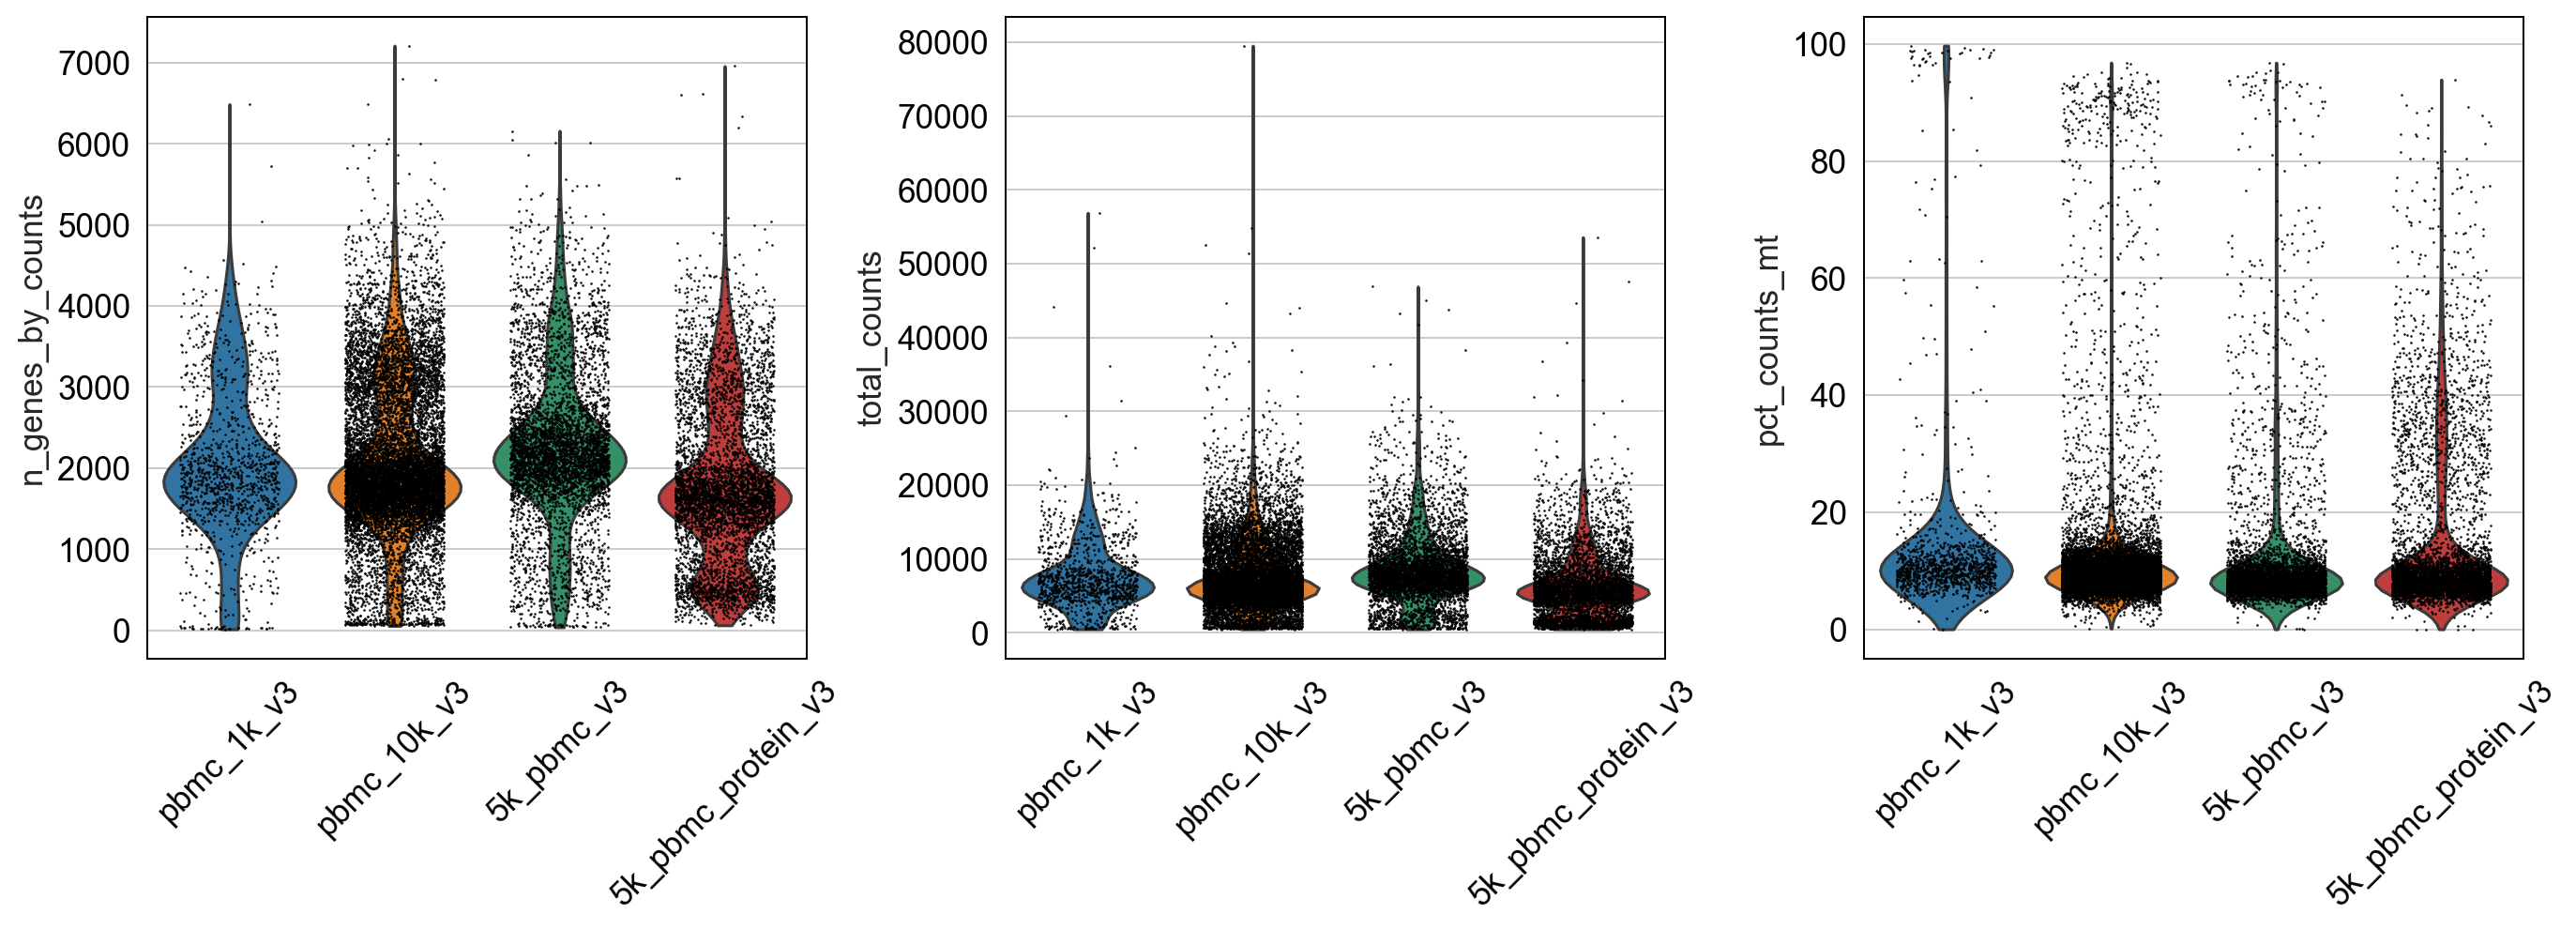

In [66]:
# Calculate quality metrics for each cell and plot them by batch
adata.var["mt"]   = adata.var_names.str.startswith("MT-")
adata.var["ribo"] = adata.var_names.str.startswith(("RPS", "RPL"))
adata.var["hb"]   = adata.var_names.str.contains("^HB[^P]")

sc.pp.calculate_qc_metrics(adata, qc_vars=["mt", "ribo", "hb"], percent_top=[20], log1p=True, inplace=True)
sc.pl.violin(adata, ["n_genes_by_counts", "total_counts", "pct_counts_mt"], groupby="batch", jitter=0.3, multi_panel=True, rotation=45)

### What this plot shows
Three violin plots, one per quality measure, split by dataset. Each dot is a cell.

- **Genes per cell:** most cells have roughly 1,500 to 2,500 genes. Cells near zero are mostly empty or broken droplets, and cells above about 5,000 may be two cells stuck together.
- **Total counts:** most cells sit below about 10,000, with a few extreme cells far above.
- **Mitochondrial percent:** most cells are below about 15%, but every dataset has a tail running up toward 100%. These are damaged cells whose own RNA has leaked out.
- **Between datasets:** the shapes differ. The 5k_pbmc_protein_v3 dataset has an extra bulge of cells with few genes, so it is the lowest quality. This is why the next cell sets cut-offs separately for each dataset instead of one cut-off for all.

In [67]:
# Flag and remove low quality cells and rarely detected genes
def mad_outlier(x, nmads):
    med = np.median(x)
    mad = median_abs_deviation(x)
    return (x < med - nmads * mad) | (x > med + nmads * mad)
by_batch = adata.obs.groupby("batch", observed=True)
out_counts = by_batch["log1p_total_counts"].transform(lambda x: mad_outlier(x, 5))
out_genes  = by_batch["log1p_n_genes_by_counts"].transform(lambda x: mad_outlier(x, 5))
out_top20  = by_batch["pct_counts_in_top_20_genes"].transform(lambda x: mad_outlier(x, 5))
out_mt     = by_batch["pct_counts_mt"].transform(lambda x: mad_outlier(x, 3)) | (adata.obs["pct_counts_mt"] > 15)

adata.obs["qc_outlier"] = out_counts | out_genes | out_top20 | out_mt
print(adata.obs.groupby("batch", observed=True)["qc_outlier"].agg(["sum", "mean"]))

adata = adata[~adata.obs["qc_outlier"]].copy()
sc.pp.filter_genes(adata, min_cells=10)
print(adata)

                     sum      mean
batch                             
pbmc_1k_v3           201  0.164484
pbmc_10k_v3         1530  0.130003
5k_pbmc_v3           765  0.152239
5k_pbmc_protein_v3  1222  0.232895
AnnData object with n_obs × n_vars = 19545 × 18727
    obs: 'batch', 'n_genes_by_counts', 'log1p_n_genes_by_counts', 'total_counts', 'log1p_total_counts', 'pct_counts_in_top_20_genes', 'total_counts_mt', 'log1p_total_counts_mt', 'pct_counts_mt', 'total_counts_ribo', 'log1p_total_counts_ribo', 'pct_counts_ribo', 'total_counts_hb', 'log1p_total_counts_hb', 'pct_counts_hb', 'qc_outlier'
    var: 'mt', 'ribo', 'hb', 'n_cells_by_counts', 'mean_counts', 'log1p_mean_counts', 'pct_dropout_by_counts', 'total_counts', 'log1p_total_counts', 'n_cells'
    uns: 'batch_colors'


## Doublet detection

... storing 'batch' as categorical


                    sum      mean
batch                            
5k_pbmc_protein_v3   87  0.021615
5k_pbmc_v3           75  0.017606
pbmc_10k_v3         500  0.048833
pbmc_1k_v3            9  0.008815


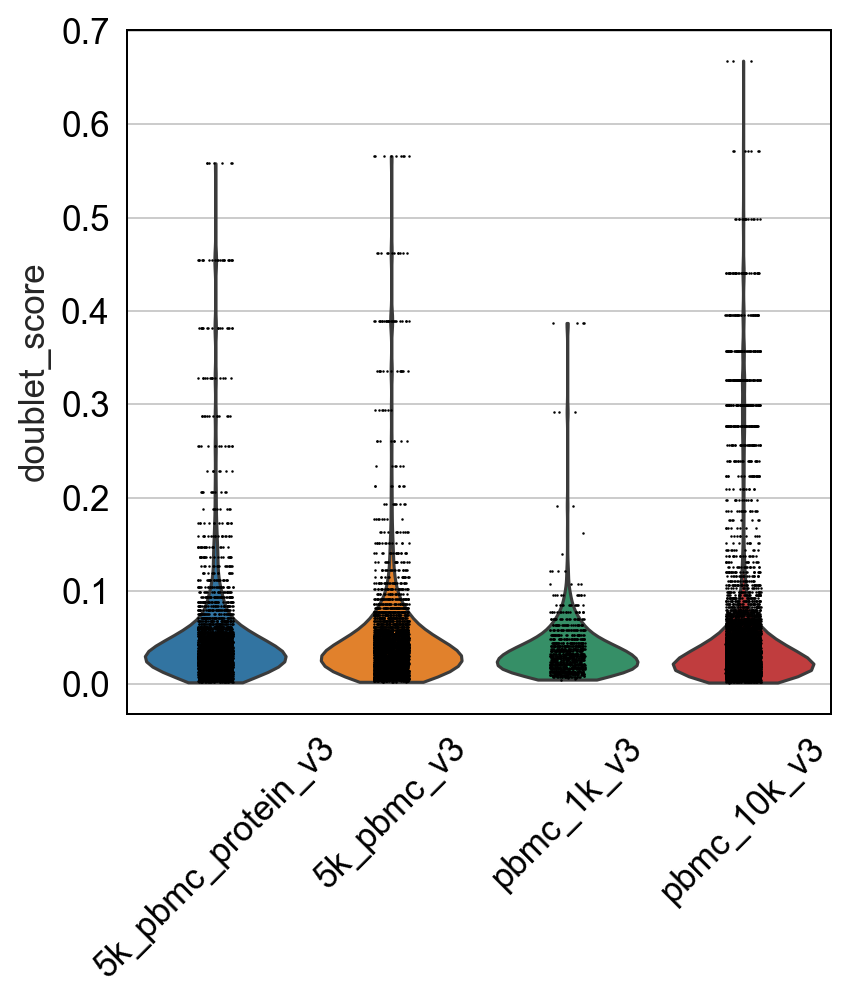

(18874, 18727)


In [68]:
# Detect and remove doublets
sc.pp.scrublet(adata, batch_key="batch", use_approx_neighbors=False)
print(adata.obs.groupby("batch", observed=True)["predicted_doublet"].agg(["sum", "mean"]))
sc.pl.violin(adata, "doublet_score", groupby="batch", rotation=45)
adata = adata[~adata.obs["predicted_doublet"]].copy()
print(adata.shape)

### What this plot shows
The doublet score of every cell, by dataset. A doublet is a droplet that captured two cells. A higher score means the cell looks more like an artificial doublet.

- Nearly all cells score below about 0.1, so the thick part of each shape is at the bottom.
- A thin tail of cells scores much higher, up to about 0.4 in the smallest dataset and about 0.67 in the 10k dataset. These are the likely doublets.
- The 10k dataset has the longest and busiest tail, which fits the fact that it loaded the most cells and so had the most accidental pairs.
- The cells predicted to be doublets are removed in the same cell.

## 5. Normalization and feature selection

In [69]:
# Normalize counts and keep the 3000 most variable genes
adata.layers["counts"] = adata.X.copy()
sc.pp.normalize_total(adata, target_sum=1e4)
sc.pp.log1p(adata)
sc.pp.highly_variable_genes(adata, n_top_genes=3000, batch_key="batch", flavor="seurat")
print("HVGs:", adata.var["highly_variable"].sum())
adata_full = adata.copy()
adata = adata[:, adata.var["highly_variable"]].copy()
sc.pp.scale(adata, max_value=10)

HVGs: 3000


## 6. PCA and the batch effect before correction

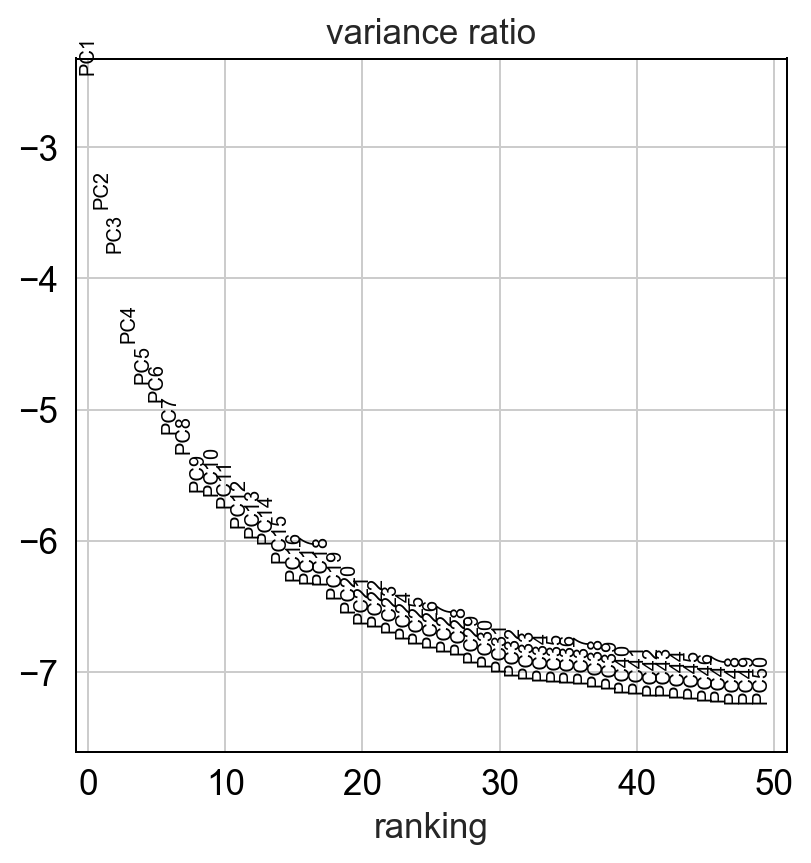

In [70]:
# Run PCA and plot how much variation each component explains
sc.tl.pca(adata, n_comps=50, svd_solver="arpack")
sc.pl.pca_variance_ratio(adata, n_pcs=50, log=True)

### What this plot shows
How much of the total variation each principal component explains. The y axis is on a log scale, so each step down is a large drop.

- The first few components explain far more than the rest, with a steep fall over roughly the first 10.
- After about 20 to 30 components the curve is nearly flat. Those later components mostly capture noise.
- This supports using the first 30 components for the next steps, since they hold the real structure and leave out most of the noise.

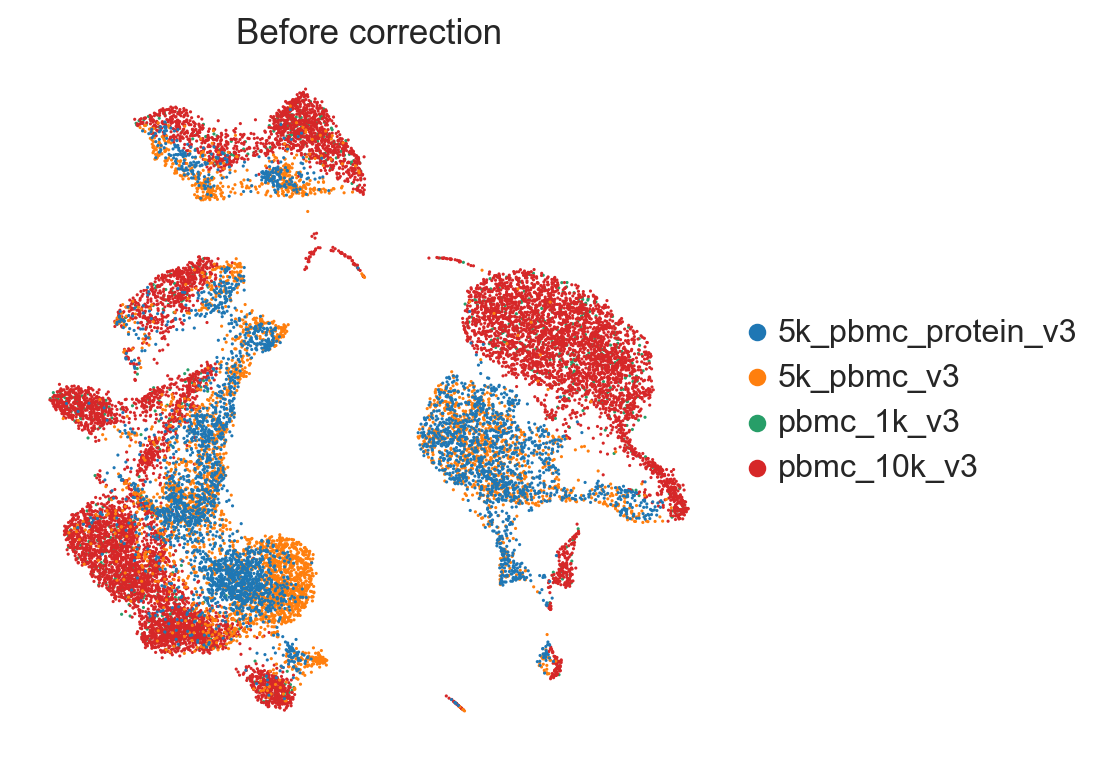

In [71]:
# Build the cell neighbor graph and UMAP before batch correction
sc.pp.neighbors(adata, n_neighbors=15, n_pcs=30, transformer="sklearn")
sc.tl.umap(adata)
adata.obsm["X_umap_uncorrected"] = adata.obsm["X_umap"].copy()
sc.pl.umap(adata, color="batch", title="Before correction")

### What this plot shows
A 2D map of all cells before batch correction, colored by dataset. Cells close together have similar gene activity.

- Cells of the same type should sit together no matter which dataset they came from. Here they do not.
- The large island on the right is split into a red part (10k) and a blue and orange part (the two 5k datasets), so cells of the same kind are being separated by dataset.
- This is the batch effect. If it is left alone, clustering would partly group cells by dataset instead of by cell type.
- The smallest dataset (1k) is drawn underneath the others and is hard to see.

## 7. Batch correction with Harmony

2026-11-08 14:56:35,220 - harmonypy - INFO - Running Harmony
Running Harmony
2026-11-08 14:56:35,220 - harmonypy - INFO -   Parameters:
  Parameters:
2026-11-08 14:56:35,221 - harmonypy - INFO -     max_iter_harmony: 10
    max_iter_harmony: 10
2026-11-08 14:56:35,222 - harmonypy - INFO -     max_iter_kmeans: 4
    max_iter_kmeans: 4
2026-11-08 14:56:35,223 - harmonypy - INFO -     epsilon_cluster: 0.001
    epsilon_cluster: 0.001
2026-11-08 14:56:35,224 - harmonypy - INFO -     epsilon_harmony: 0.01
    epsilon_harmony: 0.01
2026-11-08 14:56:35,225 - harmonypy - INFO -     nclust: 100
    nclust: 100
2026-11-08 14:56:35,225 - harmonypy - INFO -     block_size: 0.05
    block_size: 0.05
2026-11-08 14:56:35,226 - harmonypy - INFO -     lamb: dynamic (alpha=0.2)
    lamb: dynamic (alpha=0.2)
2026-11-08 14:56:35,227 - harmonypy - INFO -     theta: [2. 2. 2. 2.]
    theta: [2. 2. 2. 2.]
2026-11-08 14:56:35,227 - harmonypy - INFO -     sigma: [0.1 0.1 0.1 0.1 0.1]...
    sigma: [0.1 0.1 0.1

Harmony embedding: (18874, 50)


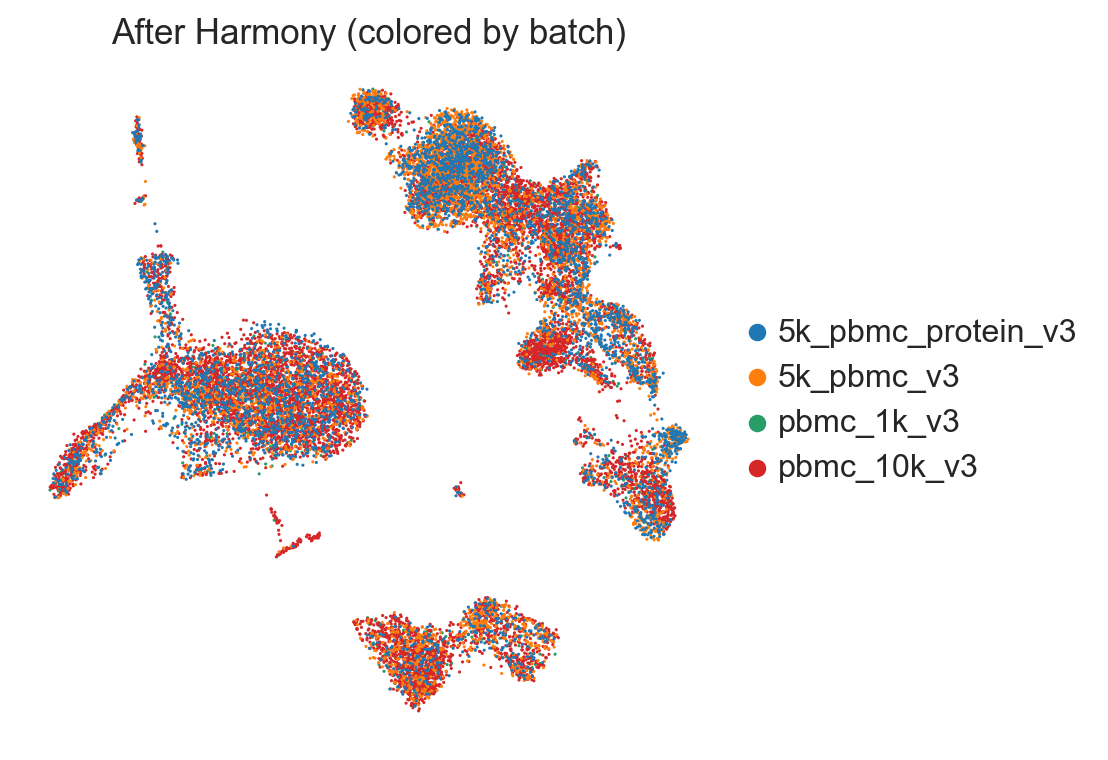

In [72]:
# Remove batch effects with Harmony and redraw the UMAP
import harmonypy
ho = harmonypy.run_harmony(adata.obsm["X_pca"], adata.obs, "batch")
Z = np.asarray(ho.Z_corr)
if Z.shape[0] != adata.n_obs:
    Z = Z.T
adata.obsm["X_pca_harmony"] = Z
print("Harmony embedding:", Z.shape)

sc.pp.neighbors(adata, use_rep="X_pca_harmony", n_neighbors=15, transformer="sklearn")
sc.tl.umap(adata)
sc.pl.umap(adata, color="batch", title="After Harmony (colored by batch)")

### What this plot shows
The same kind of map, now built from the Harmony corrected coordinates, colored by dataset.

- Colors are now mixed together inside each island, so cells of the same type from different datasets sit together.
- The separate red and blue regions seen before are gone from most islands. This matches the numbers in the next cell, where the share of same-dataset neighbors falls from 0.72 to 0.47.
- A few small patches still lean toward one color, so the correction is good but not perfect.

In [73]:
# Measure how well batches are mixed before and after Harmony
from sklearn.neighbors import NearestNeighbors
batch_codes = adata.obs["batch"].cat.codes.values
props = adata.obs["batch"].value_counts(normalize=True)
expected = float((props ** 2).sum())
for rep in ["X_pca", "X_pca_harmony"]:
    emb = adata.obsm[rep][:, :30]
    idx = NearestNeighbors(n_neighbors=31).fit(emb).kneighbors(emb, return_distance=False)[:, 1:]
    same = (batch_codes[idx] == batch_codes[:, None]).mean()
    print(f"{rep:15s} same batch neighbor fraction = {same:.3f}   (random mixing = {expected:.3f})")

X_pca           same batch neighbor fraction = 0.723   (random mixing = 0.362)
X_pca_harmony   same batch neighbor fraction = 0.466   (random mixing = 0.362)


## Clustering

0.3 14 clusters
0.6 17 clusters
1.0 18 clusters
1.5 25 clusters
2.0 29 clusters


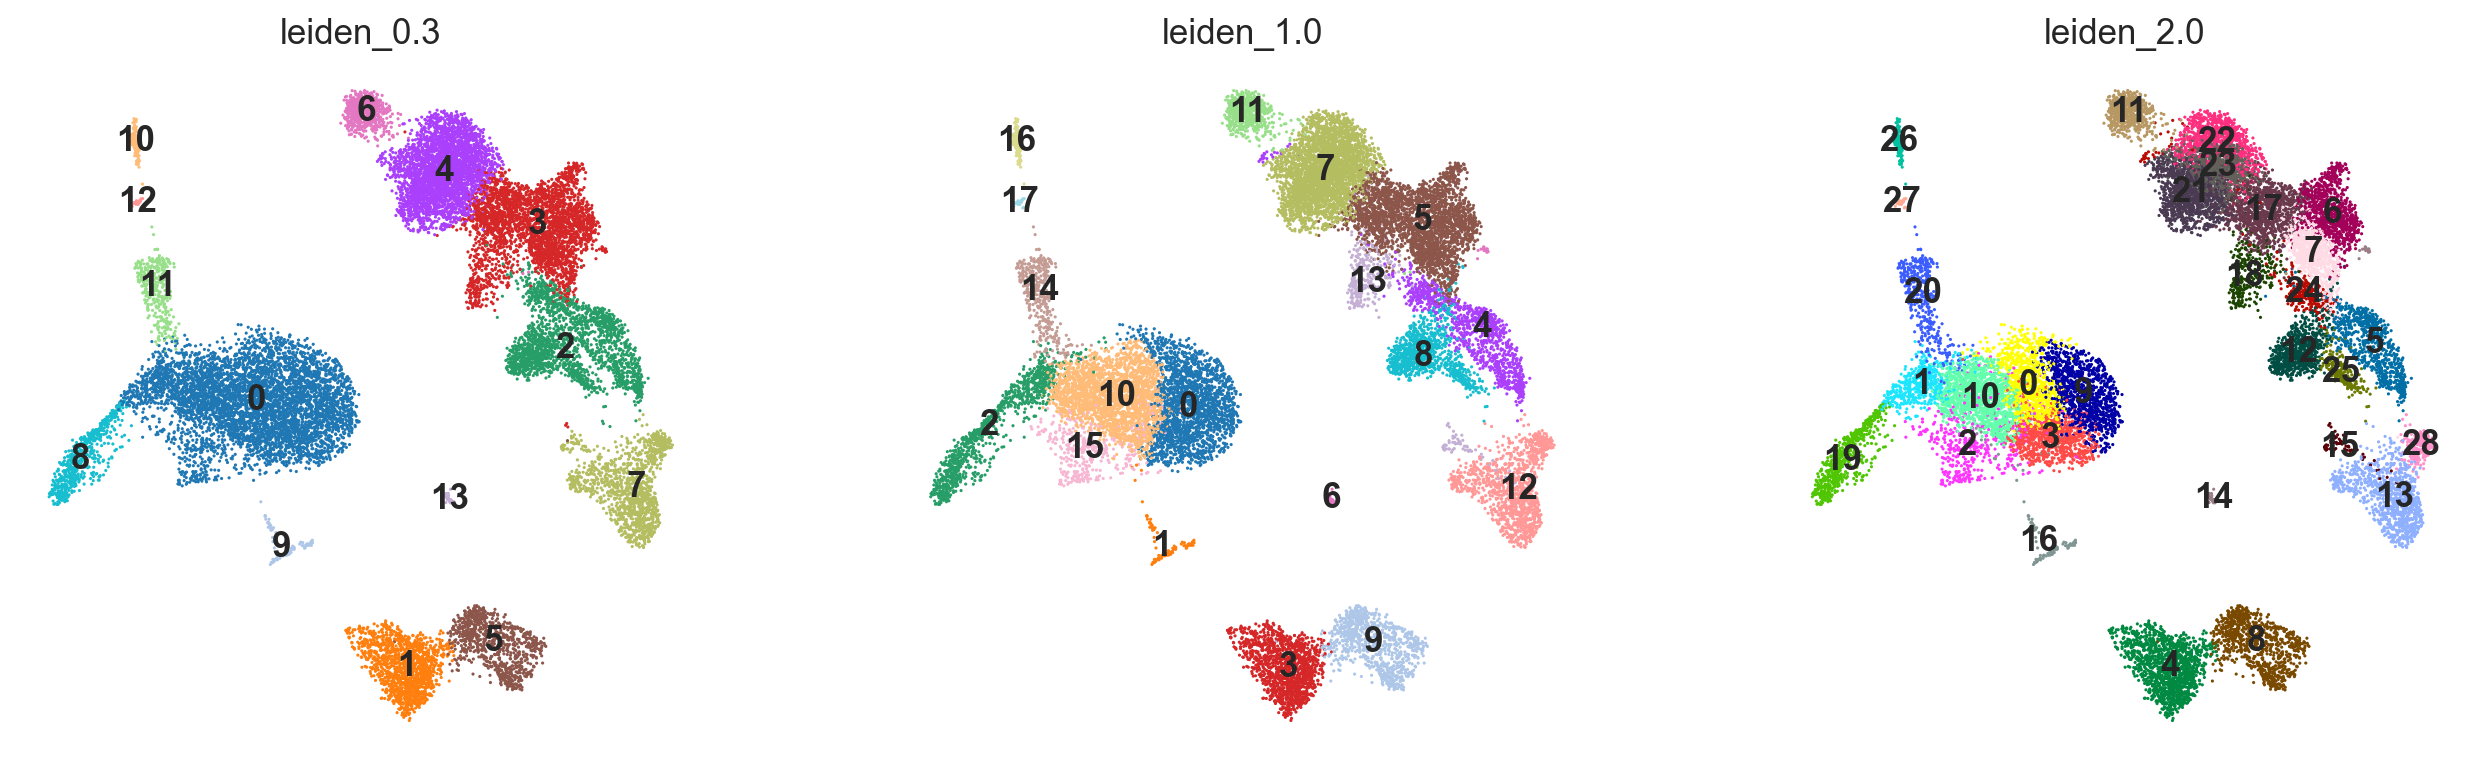

In [74]:
# Cluster the cells at several resolutions and plot the results
for res in [0.3, 0.6, 1.0, 1.5, 2.0]:
    sc.tl.leiden(adata, resolution=res, key_added=f"leiden_{res}", flavor="igraph", n_iterations=2, directed=False)
    print(res, adata.obs[f"leiden_{res}"].nunique(), "clusters")
sc.pl.umap(adata, color=["leiden_0.3", "leiden_1.0", "leiden_2.0"], legend_loc="on data", ncols=3)

### What this plot shows
The same map colored by clusters at three different resolutions (0.3, 1.0 and 2.0). Higher resolution means more and smaller clusters.

- The main islands are the same at every setting. The B cell island, the monocyte island and the T and NK region all stay recognizable.
- At 0.3 there are only 14 big clusters, so different cell types can be lumped together.
- At 2.0 there are 29 clusters, and the T cell region and the monocyte island are chopped into many small pieces. Many of these cuts are likely arbitrary.
- 1.0 is a middle choice (18 clusters) that splits the main types without over-cutting, and this is the one used from here on.

In [75]:
# Choose the final clustering and copy labels to the full gene object
adata.obs["cluster"] = adata.obs["leiden_1.0"]
adata_full.obs = adata.obs.copy()
adata_full.obsm["X_umap"] = adata.obsm["X_umap"]
adata_full.obsm["X_pca_harmony"] = adata.obsm["X_pca_harmony"]

## Marker based cell type annotation- two levels
**Level 1: broad lineages.**
**Level 2: subtypes.**

Plasma cells: missing ['SDC1']
Erythrocytes: missing ['ALAS2']


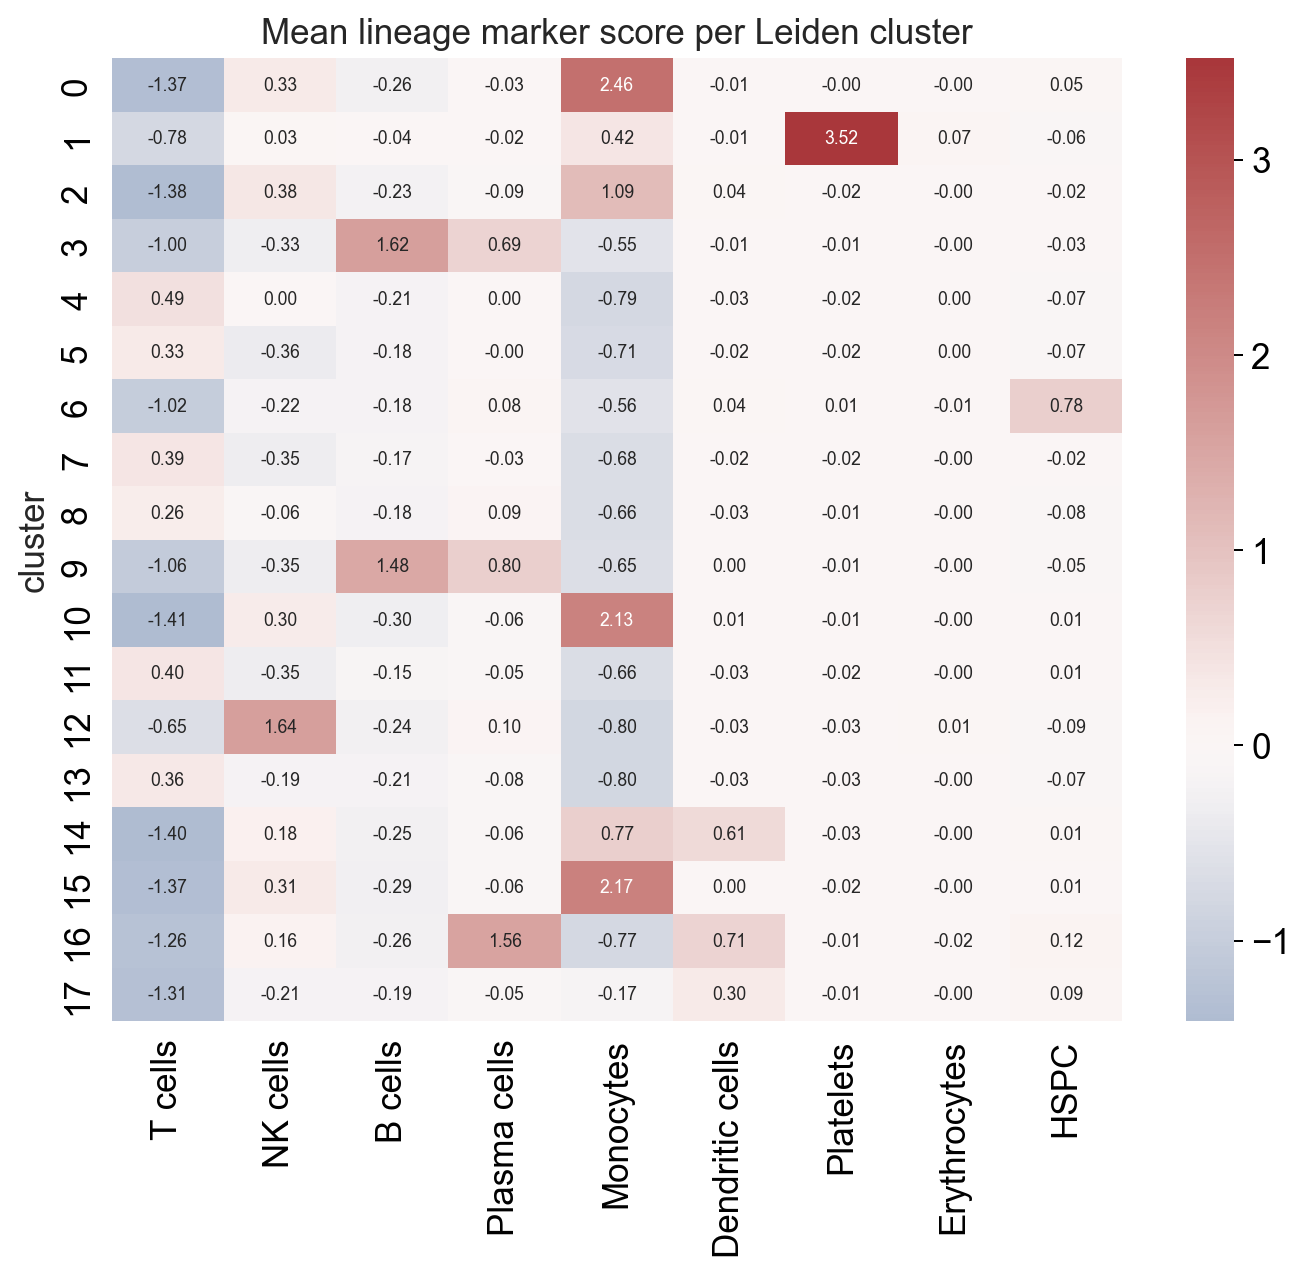

In [76]:
# Score each cluster for broad cell lineage markers and plot a heatmap
lineage_markers = {
    "T cells":        ["CD3D", "CD3E", "CD3G", "TRAC", "TRBC2", "LCK"],
    "NK cells":       ["KLRF1", "NCAM1", "KLRC1", "KLRD1", "TYROBP", "FCER1G", "GNLY"],
    "B cells":        ["MS4A1", "CD79A", "CD79B", "CD19", "BANK1", "CD22"],
    "Plasma cells":   ["JCHAIN", "MZB1", "SDC1", "XBP1", "TNFRSF17", "IGKC"],
    "Monocytes":      ["LYZ", "CD14", "S100A8", "S100A9", "VCAN", "FCN1", "MS4A7", "LST1"],
    "Dendritic cells":["FCER1A", "CD1C", "CLEC10A", "LILRA4", "IL3RA", "CLEC4C", "CLEC9A", "XCR1"],
    "Platelets":      ["PPBP", "PF4", "GNG11", "TUBB1", "CAVIN2"],
    "Erythrocytes":   ["HBB", "HBA1", "HBA2", "ALAS2", "SLC4A1"],
    "HSPC":           ["CD34", "SPINK2", "KIT", "CRHBP", "SOX4"],
}

lineage_markers_present = {}
for name, genes in lineage_markers.items():
    present = [g for g in genes if g in adata_full.var_names]
    missing = [g for g in genes if g not in adata_full.var_names]
    if missing:
        print(f"{name}: missing {missing}")
    lineage_markers_present[name] = present

for name, genes in lineage_markers_present.items():
    sc.tl.score_genes(adata_full, genes, score_name=f"broad_{name}", use_raw=False)

broad_cols = [f"broad_{n}" for n in lineage_markers_present]
cluster_scores = adata_full.obs.groupby("cluster", observed=True)[broad_cols].mean()
cluster_scores.columns = [c.replace("broad_", "") for c in cluster_scores.columns]
plt.figure(figsize=(9, 0.28 * len(cluster_scores) + 2))
sns.heatmap(cluster_scores, cmap="vlag", center=0, annot=True, fmt=".2f", annot_kws={"size": 7})
plt.title("Mean lineage marker score per Leiden cluster")
plt.show()

### What this plot shows
A heatmap with one row per cluster and one column per cell family. Each number is the cluster's average marker score for that family. Red means the markers are higher than expected by chance, blue means lower.

- Most clusters have one clear red cell: clusters 0, 10 and 15 for monocytes (about 2.1 to 2.5), cluster 1 for platelets (3.52), clusters 3 and 9 for B cells, cluster 12 for NK cells, cluster 6 for HSPC (blood stem cells) and cluster 16 for plasma cells.
- T cell clusters (4, 5, 7, 8, 11, 13) are only weakly red, because T cell genes are active in many cell types and the scores are small.
- Clusters 14 and 17 have no strong winner. Cluster 14 scores 0.77 for monocytes and 0.61 for dendritic cells, so the label for that cluster is uncertain.
- The Erythrocytes column is empty everywhere, so no red blood cell cluster exists in this data.

In [77]:
# Assign a broad label to each cluster with a confidence margin
broad_map = cluster_scores.idxmax(axis=1)
sorted_scores = np.sort(cluster_scores.values, axis=1)
margin = pd.Series(sorted_scores[:, -1] - sorted_scores[:, -2], index=cluster_scores.index)

broad_table = pd.DataFrame({"broad_label": broad_map, "top_score": sorted_scores[:, -1].round(2), "margin_to_2nd": margin.round(2), "n_cells": adata_full.obs["cluster"].value_counts().reindex(cluster_scores.index)})
display(broad_table)

,broad_label,top_score,margin_to_2nd,n_cells
cluster,,,,
0,Monocytes,2.46,2.14,1959
1,Platelets,3.52,3.10,91
2,Monocytes,1.09,0.71,999
3,B cells,1.62,0.93,1377
4,T cells,0.49,0.48,1059
5,T cells,0.33,0.33,2812
6,HSPC,0.78,0.70,51
7,T cells,0.39,0.39,3176
8,T cells,0.26,0.17,978


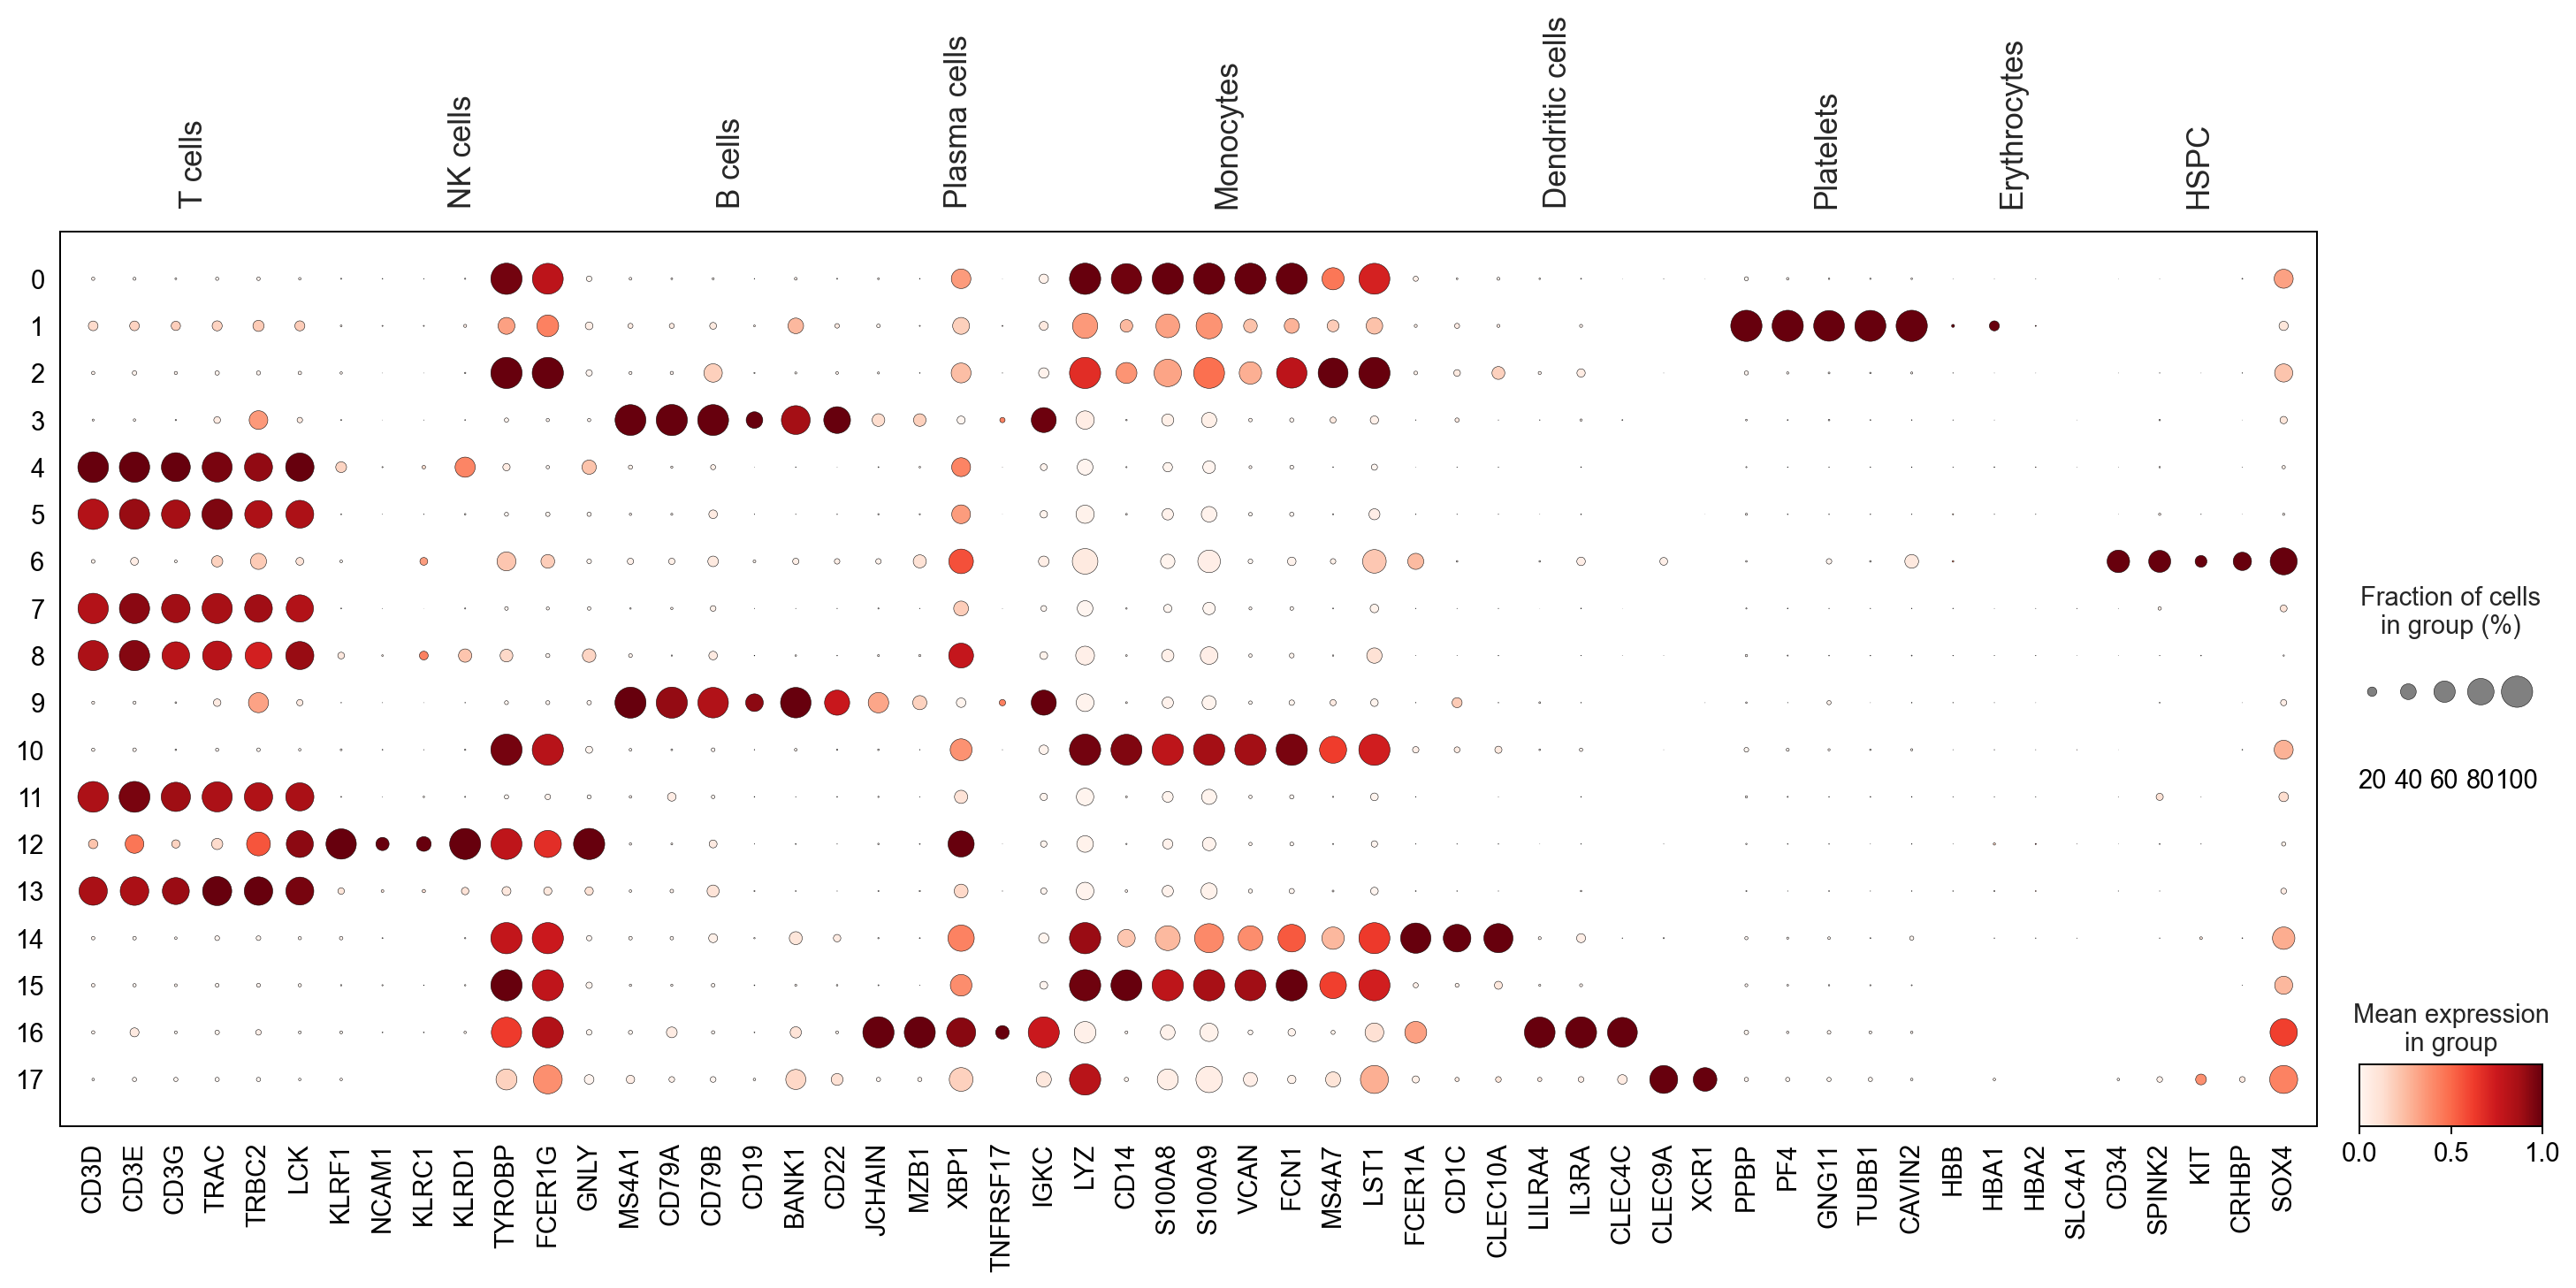

In [78]:
# Plot a dot plot of lineage markers for each cluster
sc.pl.dotplot(adata_full, lineage_markers_present, groupby="cluster", standard_scale="var", dendrogram=False, figsize=(20, 0.3 * len(cluster_scores) + 2))

### What this plot shows
A dot plot of lineage marker genes for each cluster. Bigger dots mean more of the cluster's cells express the gene, and darker color means higher average expression.

- The pattern confirms the heatmap at the level of single genes. Clusters 4, 5, 7, 8, 11 and 13 light up for T cell genes (CD3D, CD3E, TRAC), cluster 12 for NK genes (KLRF1, KLRD1, GNLY), clusters 3 and 9 for B cell genes (MS4A1, CD79A), clusters 0, 2, 10 and 15 for monocyte genes (LYZ, S100A8, CD14), cluster 1 for platelet genes (PPBP, PF4) and cluster 6 for stem cell genes (CD34, SPINK2).
- **Cluster 14** is bright for CD1C, FCER1A and CLEC10A, which are dendritic cell genes, although the score table called it Monocytes. It looks like a dendritic cell group.
- **Cluster 16** is labeled plasma cells, but it is bright for LILRA4, IL3RA and CLEC4C. These are markers of plasmacytoid dendritic cells, so this cluster is probably that cell type.
- **Cluster 17** is bright for CLEC9A and XCR1, another dendritic cell type.
- Red blood cell genes (HBB, HBA1, HBA2, SLC4A1) are barely expressed anywhere.

... storing 'broad' as categorical


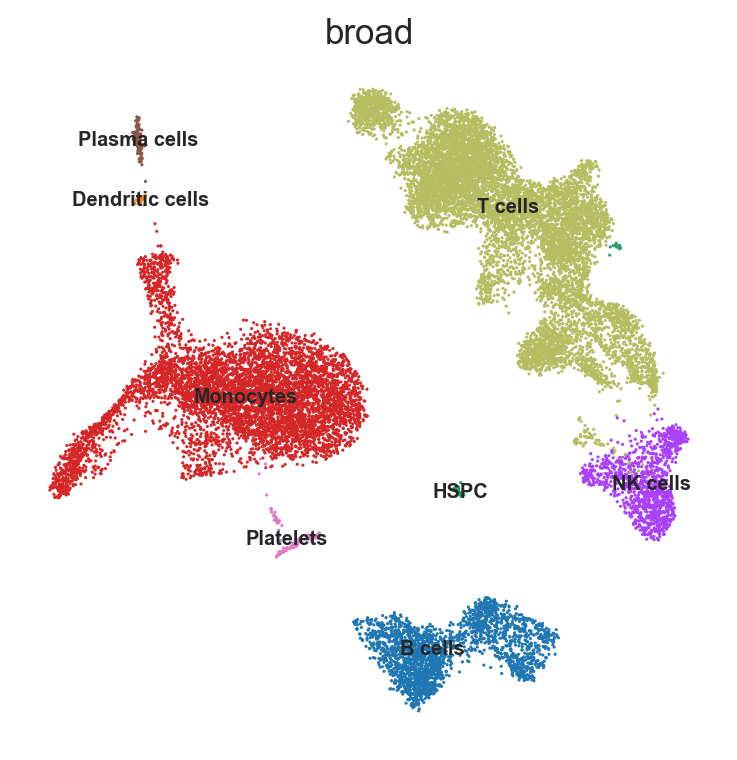

broad
T cells            8979
Monocytes          6136
B cells            2286
NK cells           1181
Plasma cells        121
Platelets            91
HSPC                 51
Dendritic cells      29
Name: count, dtype: int64

In [79]:
# Apply any manual label changes and add broad labels to the cells
manual_overrides = {}
for cl, label in manual_overrides.items():
    broad_map[cl] = label
adata.obs["broad"] = adata.obs["cluster"].map(broad_map).astype(str)
adata_full.obs["broad"] = adata.obs["broad"]
sc.pl.umap(adata, color=["broad"], legend_loc="on data", legend_fontsize=8)
adata.obs["broad"].value_counts()

### What this plot shows
The map colored by the broad lineage label.

- T cells form the large region at the top right, with NK cells attached at its lower edge.
- Monocytes form the big island on the left with a tail on its left side and a thin stalk reaching up toward the dendritic cell and plasma cell labels.
- B cells form a separate island at the bottom.
- Platelets, HSPC, plasma cells and dendritic cells are tiny isolated patches.
- The grouping is clean at the broad level: each family occupies its own area of the map. The finer splits come next.

### Level 2: subtype markers- each lineage re clustered and scored separately

In [80]:
# Define subtype markers and score every cell for each subtype
subtype_markers = {
    "T cells": {
        "CD4 Naive T":          ["CD4", "CCR7", "SELL", "LEF1", "TCF7", "IL7R"],
        "CD4 Memory T":         ["IL7R", "S100A4", "LTB", "AQP3", "CD4", "CD40LG", "ANXA1"],
        "CD4 Treg":             ["FOXP3", "IL2RA", "CTLA4", "TIGIT", "IKZF2", "BATF"],
        "CD8 Naive T":          ["CD8A", "CD8B", "CCR7", "LEF1", "TCF7", "SELL"],
        "CD8 TEM (GZMK+)":      ["CD8A", "CD8B", "GZMK", "CCL5", "DUSP2", "CMC1"],
        "CD8 TEMRA/CTL":        ["CD8A", "GZMH", "GZMB", "PRF1", "NKG7", "CX3CR1", "FGFBP2"],
        "MAIT":                 ["SLC4A10", "KLRB1", "ZBTB16", "TRAV1-2", "CCR6", "RORC"],
        "gd T":                 ["TRDC", "TRGC1", "TRGC2", "TRDV2", "TRGV9"],
    },
    "NK cells": {
        "NK CD56dim":           ["FCGR3A", "NKG7", "GNLY", "PRF1", "FGFBP2", "SPON2"],
        "NK CD56bright":        ["NCAM1", "XCL1", "XCL2", "SELL", "GZMK", "KLRC1"],
    },
    "B cells": {
        "B Naive":              ["MS4A1", "CD79A", "IGHD", "TCL1A", "FCER2", "IL4R"],
        "B Memory":             ["MS4A1", "CD79A", "CD27", "TNFRSF13B", "AIM2", "SSPN"],
    },
    "Monocytes": {
        "CD14 Mono":            ["CD14", "LYZ", "S100A8", "S100A9", "VCAN", "CSF3R"],
        "CD16 Mono":            ["FCGR3A", "MS4A7", "LST1", "AIF1", "IFITM3", "CDKN1C"],
    },
    "Dendritic cells": {
        "cDC2":                 ["CD1C", "FCER1A", "CLEC10A", "CD1E"],
        "pDC":                  ["LILRA4", "IL3RA", "CLEC4C", "TCF4", "IRF7", "GZMB"],
        "cDC1":                 ["CLEC9A", "XCR1", "BATF3"],
    },
}

for lineage, subs in subtype_markers.items():
    for sub_name, genes in subs.items():
        present = [g for g in genes if g in adata_full.var_names]
        sc.tl.score_genes(adata_full, present, score_name=f"sub_{sub_name}", use_raw=False)

In [81]:
# Re cluster each lineage and label the subclusters by subtype scores
adata.obs["cell_type"] = adata.obs["broad"].astype(str)
sub_resolution = 1.0

for lineage, subs in subtype_markers.items():
    mask = (adata.obs["broad"] == lineage).values
    if mask.sum() < 50:
        print(f"{lineage}: only {mask.sum()} cells, keeping broad label")
        continue

    sub = adata[mask].copy()
    sc.pp.neighbors(sub, use_rep="X_pca_harmony", n_neighbors=15, transformer="sklearn")
    sc.tl.leiden(sub, resolution=sub_resolution, key_added="subcluster", flavor="igraph", n_iterations=2, directed=False)

    sub_cols = [f"sub_{n}" for n in subs]
    tmp = adata_full.obs.loc[sub.obs_names, sub_cols].copy()
    tmp["subcluster"] = sub.obs["subcluster"].values
    means = tmp.groupby("subcluster", observed=True)[sub_cols].mean()
    means.columns = [c.replace("sub_", "") for c in means.columns]

    labels = means.idxmax(axis=1)
    srt = np.sort(means.values, axis=1)
    means["label"] = labels
    means["margin"] = (srt[:, -1] - srt[:, -2]).round(2)
    means["n_cells"] = sub.obs["subcluster"].value_counts().reindex(means.index)

    adata.obs.loc[sub.obs_names, "cell_type"] = sub.obs["subcluster"].map(labels).astype(str).values
    adata.obs.loc[sub.obs_names, "subcluster"] = sub.obs["subcluster"].astype(str).values

    print(f"\n=== {lineage} ({mask.sum()} cells, {means.shape[0]} subclusters) ===")
    display(means.round(2))


=== T cells (8979 cells, 13 subclusters) ===


,CD4 Naive T,CD4 Memory T,CD4 Treg,CD8 Naive T,CD8 TEM (GZMK+),CD8 TEMRA/CTL,MAIT,gd T,label,margin,n_cells
subcluster,,,,,,,,,,,
0,-0.42,0.32,0.15,-0.01,1.31,0.95,-0.01,0.31,CD8 TEM (GZMK+),0.36,739
1,0.14,1.27,0.02,-0.25,-0.12,-0.45,0.19,-0.05,CD4 Memory T,1.07,792
2,0.18,1.12,-0.00,-0.23,0.36,-0.40,0.17,-0.01,CD4 Memory T,0.76,888
3,0.39,0.24,-0.04,0.72,0.42,-0.25,-0.08,-0.05,CD8 Naive T,0.30,605
4,-0.10,1.09,0.03,-0.26,0.89,0.14,0.69,0.23,CD4 Memory T,0.20,734
5,-0.56,0.15,0.12,-0.35,0.25,0.80,0.06,0.26,CD8 TEMRA/CTL,0.54,63
6,0.42,0.85,0.02,0.09,-0.10,-0.45,0.07,-0.06,CD4 Memory T,0.43,1167
7,0.56,0.51,-0.04,0.26,-0.06,-0.45,-0.08,-0.06,CD4 Naive T,0.04,455
8,0.01,0.49,0.39,-0.10,-0.06,-0.43,-0.01,-0.08,CD4 Memory T,0.11,358



=== NK cells (1181 cells, 8 subclusters) ===


,NK CD56dim,NK CD56bright,label,margin,n_cells
subcluster,,,,,
0,2.65,0.06,NK CD56dim,2.59,99
1,2.59,-0.11,NK CD56dim,2.70,198
2,2.40,0.14,NK CD56dim,2.27,120
3,1.76,0.66,NK CD56dim,1.10,196
4,2.79,-0.15,NK CD56dim,2.94,164
5,2.37,0.00,NK CD56dim,2.37,117
6,1.19,1.17,NK CD56dim,0.02,70
7,2.46,-0.31,NK CD56dim,2.76,217



=== B cells (2286 cells, 7 subclusters) ===


,B Naive,B Memory,label,margin,n_cells
subcluster,,,,,
0,1.95,0.75,B Naive,1.20,462
1,1.85,0.68,B Naive,1.17,497
2,0.74,1.02,B Memory,0.28,236
3,1.83,0.72,B Naive,1.11,378
4,0.93,1.02,B Memory,0.09,476
5,0.68,1.10,B Memory,0.42,183
6,1.52,0.86,B Naive,0.66,54



=== Monocytes (6136 cells, 11 subclusters) ===


,CD14 Mono,CD16 Mono,label,margin,n_cells
subcluster,,,,,
0,2.79,0.48,CD14 Mono,2.31,479
1,2.62,0.52,CD14 Mono,2.10,419
2,2.68,0.38,CD14 Mono,2.31,863
3,2.42,0.62,CD14 Mono,1.79,436
4,2.54,0.52,CD14 Mono,2.03,690
5,2.15,0.49,CD14 Mono,1.66,915
6,0.97,0.22,CD14 Mono,0.75,448
7,1.37,0.81,CD14 Mono,0.56,500
8,2.97,0.39,CD14 Mono,2.57,849


Dendritic cells: only 29 cells, keeping broad label


... storing 'subcluster' as categorical


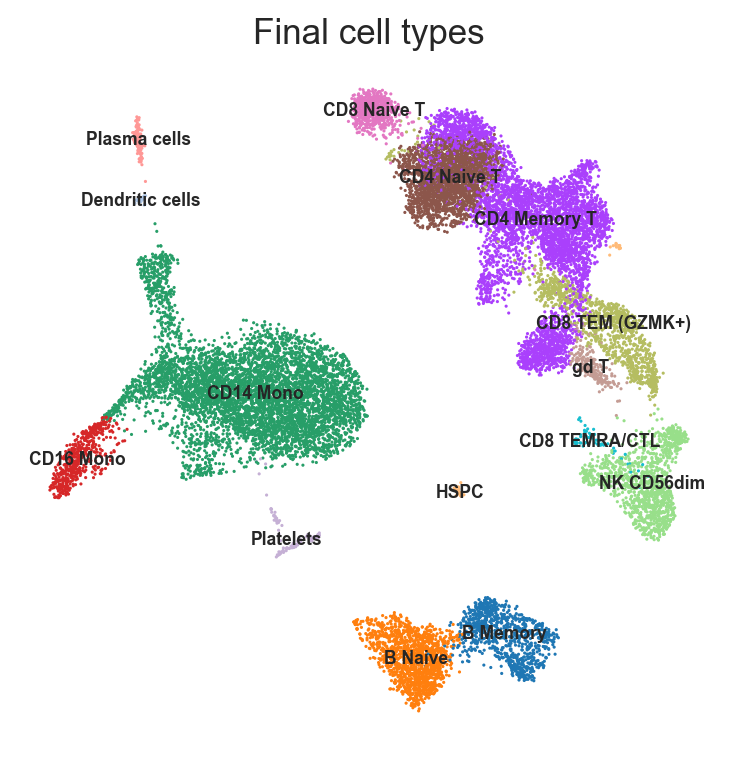

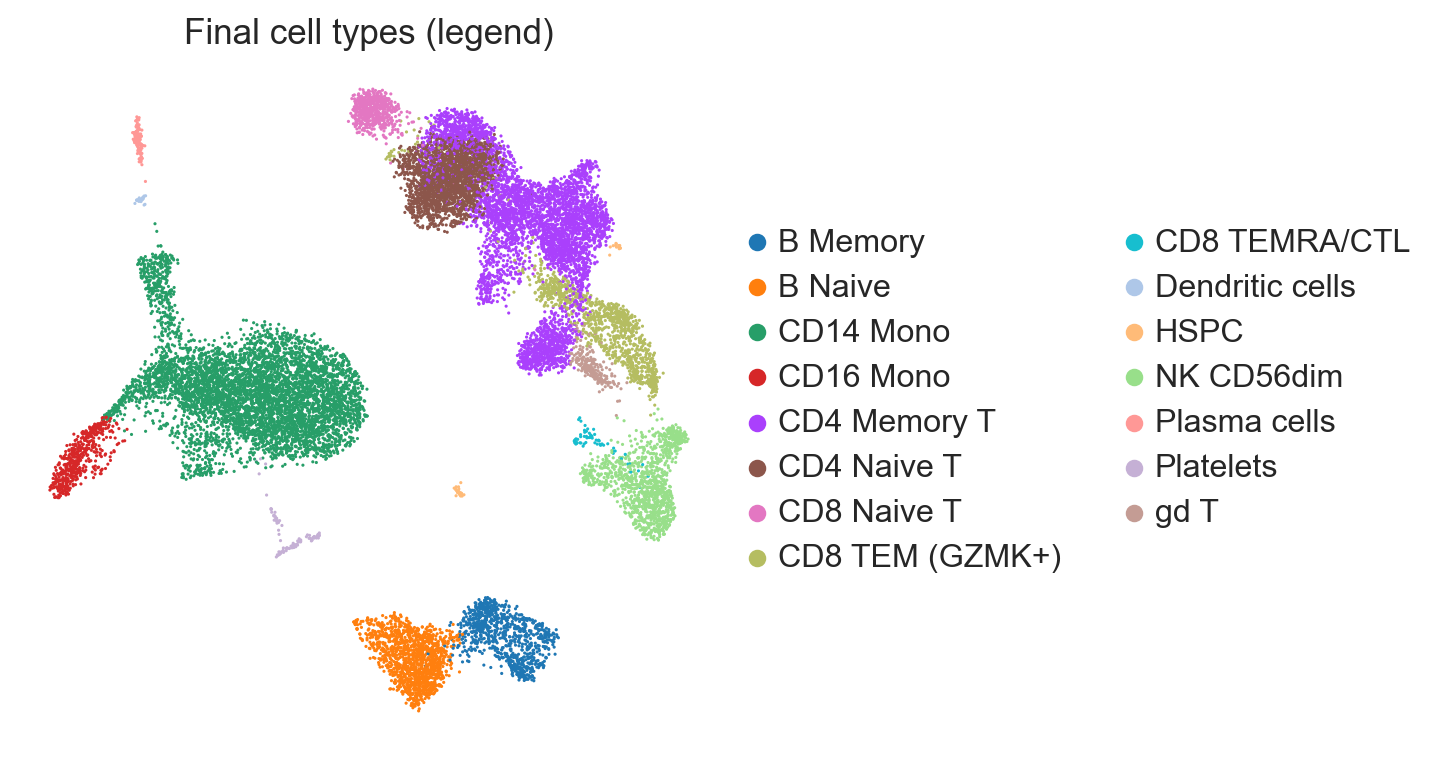

cell_type
CD14 Mono          5636
CD4 Memory T       4751
CD4 Naive T        2259
B Naive            1391
NK CD56dim         1181
CD8 TEM (GZMK+)    1076
B Memory            895
CD8 Naive T         605
CD16 Mono           500
gd T                225
Plasma cells        121
Platelets            91
CD8 TEMRA/CTL        63
HSPC                 51
Dendritic cells      29
Name: count, dtype: int64


In [82]:
# Save final cell type labels and plot the final UMAP
adata.obs["cell_type"] = adata.obs["cell_type"].astype("category")
adata_full.obs["cell_type"] = adata.obs["cell_type"]
adata_full.obs["subcluster"] = adata.obs["subcluster"]
adata_full.obs["broad"] = adata.obs["broad"]
sc.pl.umap(adata, color="cell_type", legend_loc="on data", legend_fontsize=7, title="Final cell types")
sc.pl.umap(adata, color="cell_type", title="Final cell types (legend)")
print(adata.obs["cell_type"].value_counts())

### What these plots show
The same map twice, colored by the 15 final cell types. The first has labels written on the map and the second has a legend.

- Monocytes, B cells and the T and NK region remain the three main areas. CD16 monocytes form a small group at the tip of the monocyte island, and B Naive and B Memory sit side by side as two connected lobes.
- Within the T cell area, the CD4 Naive, CD4 Memory and CD8 groups blend into one another with no clean borders. These types change gradually into one another, so the boundaries between them are partly a matter of where the cut was made. This matches the very small margins seen for several T subclusters.
- The smallest types (Plasma cells, Dendritic cells, HSPC, Platelets, CD8 TEMRA/CTL) are only a few dozen to a little over a hundred cells and show as tiny patches.

## Validating the annotation

... storing 'subcluster' as categorical


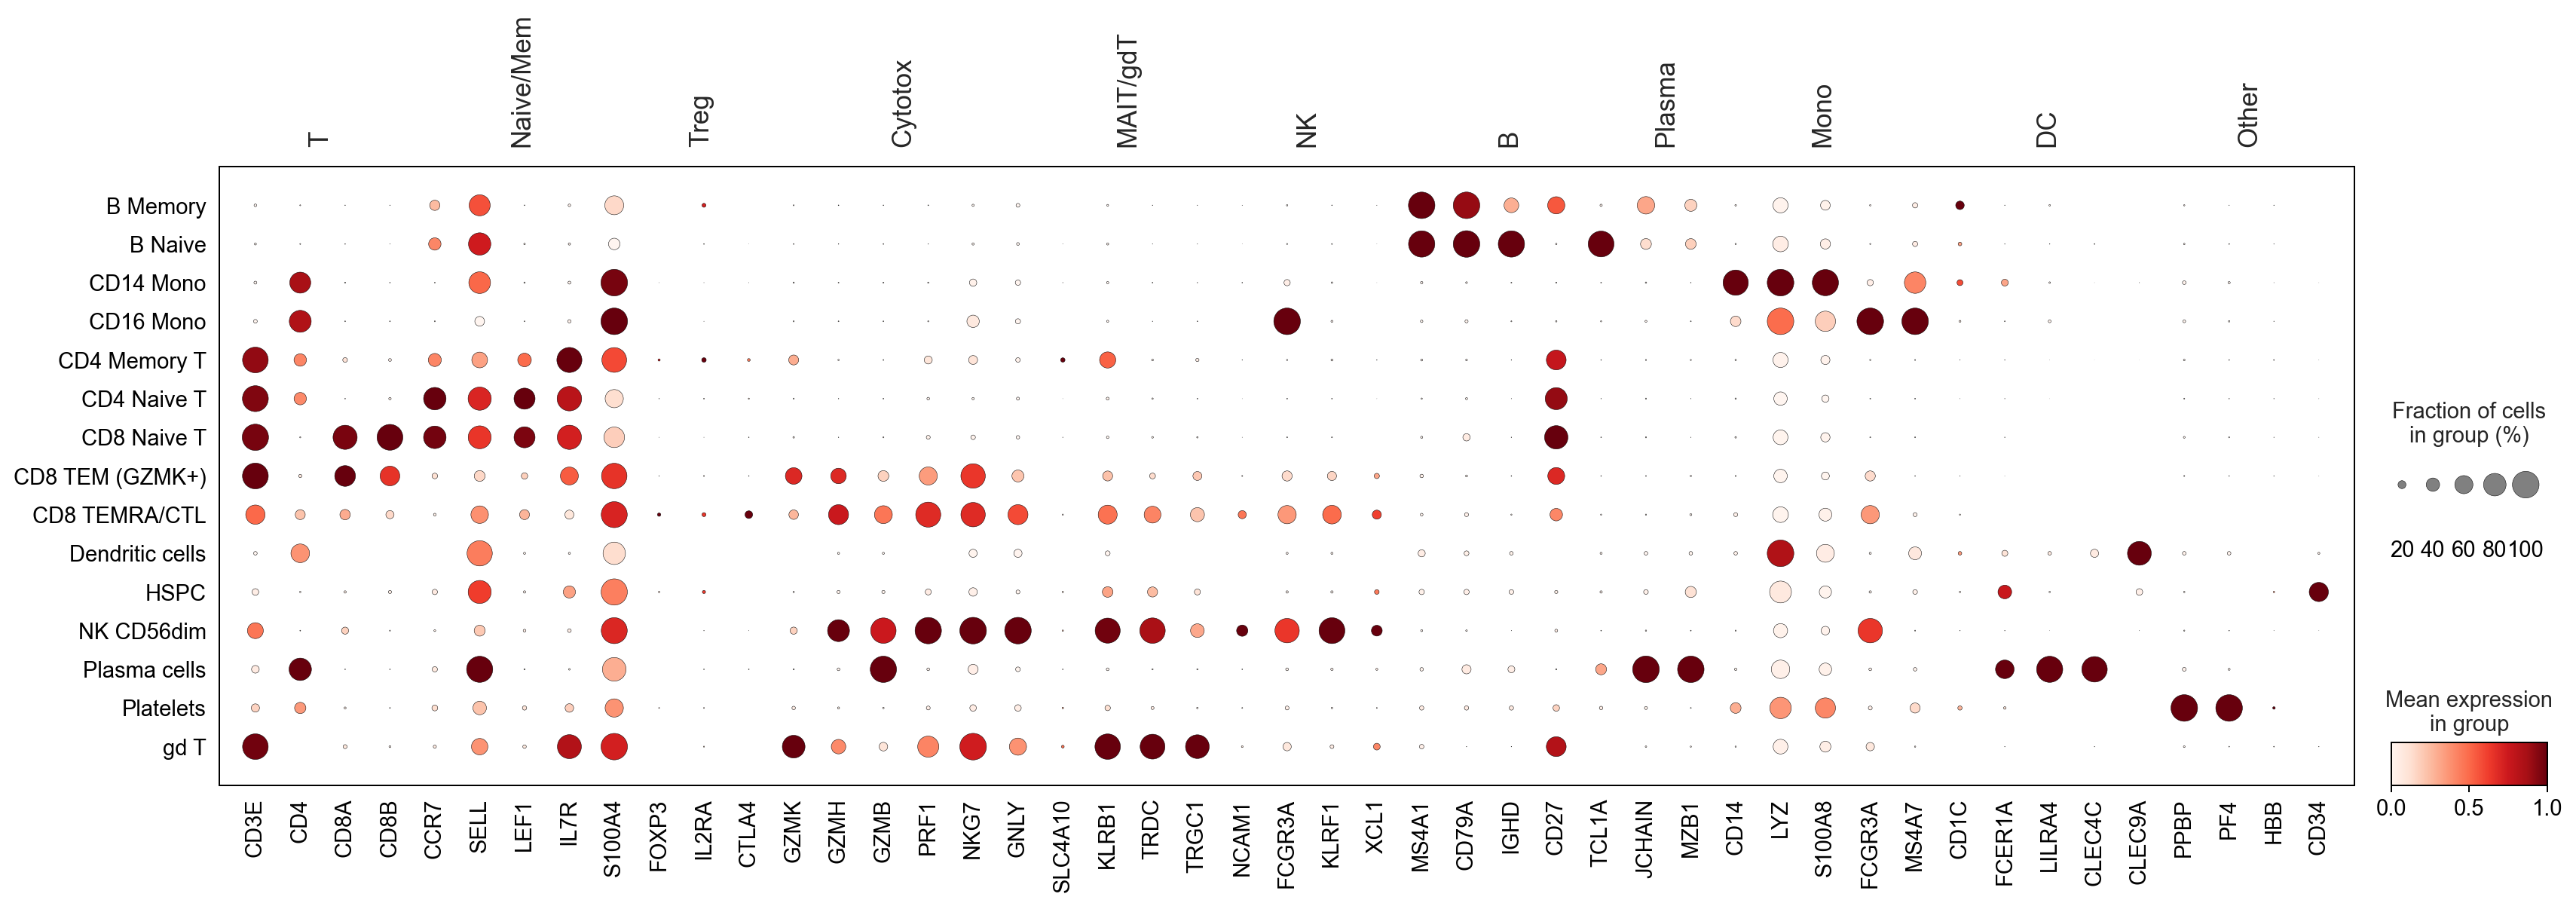

In [83]:
# Plot a dot plot of known marker genes for each final cell type
check_genes = {
    "T":        ["CD3E", "CD4", "CD8A", "CD8B"],
    "Naive/Mem": ["CCR7", "SELL", "LEF1", "IL7R", "S100A4"],
    "Treg":     ["FOXP3", "IL2RA", "CTLA4"],
    "Cytotox":  ["GZMK", "GZMH", "GZMB", "PRF1", "NKG7", "GNLY"],
    "MAIT/gdT": ["SLC4A10", "KLRB1", "TRDC", "TRGC1"],
    "NK":       ["NCAM1", "FCGR3A", "KLRF1", "XCL1"],
    "B":        ["MS4A1", "CD79A", "IGHD", "CD27", "TCL1A"],
    "Plasma":   ["JCHAIN", "MZB1", "SDC1"],
    "Mono":     ["CD14", "LYZ", "S100A8", "FCGR3A", "MS4A7"],
    "DC":       ["CD1C", "FCER1A", "LILRA4", "CLEC4C", "CLEC9A"],
    "Other":    ["PPBP", "PF4", "HBB", "CD34"],
}
check_genes = {k: [g for g in v if g in adata_full.var_names] for k, v in check_genes.items()}
sc.pl.dotplot(adata_full, check_genes, groupby="cell_type", standard_scale="var", dendrogram=False, figsize=(22, 6))

### What this plot shows
A dot plot of known marker genes (columns) for each final cell type (rows). Bigger dots mean more cells express the gene, and darker means higher average expression.

**Types that look right**
- B Naive has IGHD and TCL1A, while B Memory has CD27.
- CD14 Mono has CD14 and S100A8, while CD16 Mono has FCGR3A and MS4A7.
- NK CD56dim is high for KLRF1, GNLY, GZMB, PRF1 and NKG7.
- Platelets have PPBP and PF4, and HSPC has CD34.
- CD4 Naive T is high for CCR7 and LEF1, while CD4 Memory T is stronger for IL7R. CD8 Naive T and CD8 TEM carry CD8A and CD8B.

**Types that look wrong or unclear**
- **Plasma cells:** the row is bright for LILRA4, CLEC4C and FCER1A as well as JCHAIN and MZB1. This points to plasmacytoid dendritic cells.
- **Dendritic cells:** the row is bright for CLEC9A, so these 29 cells are the cDC1 type.
- **CD8 TEMRA/CTL:** the row mixes T cell, killer cell and NK genes, with only weak CD8A and CD8B. It is not a clean cytotoxic T type.
- **Treg and MAIT:** FOXP3, IL2RA, CTLA4 and SLC4A10 are low in every row, so no group of these cells was captured by the labels.

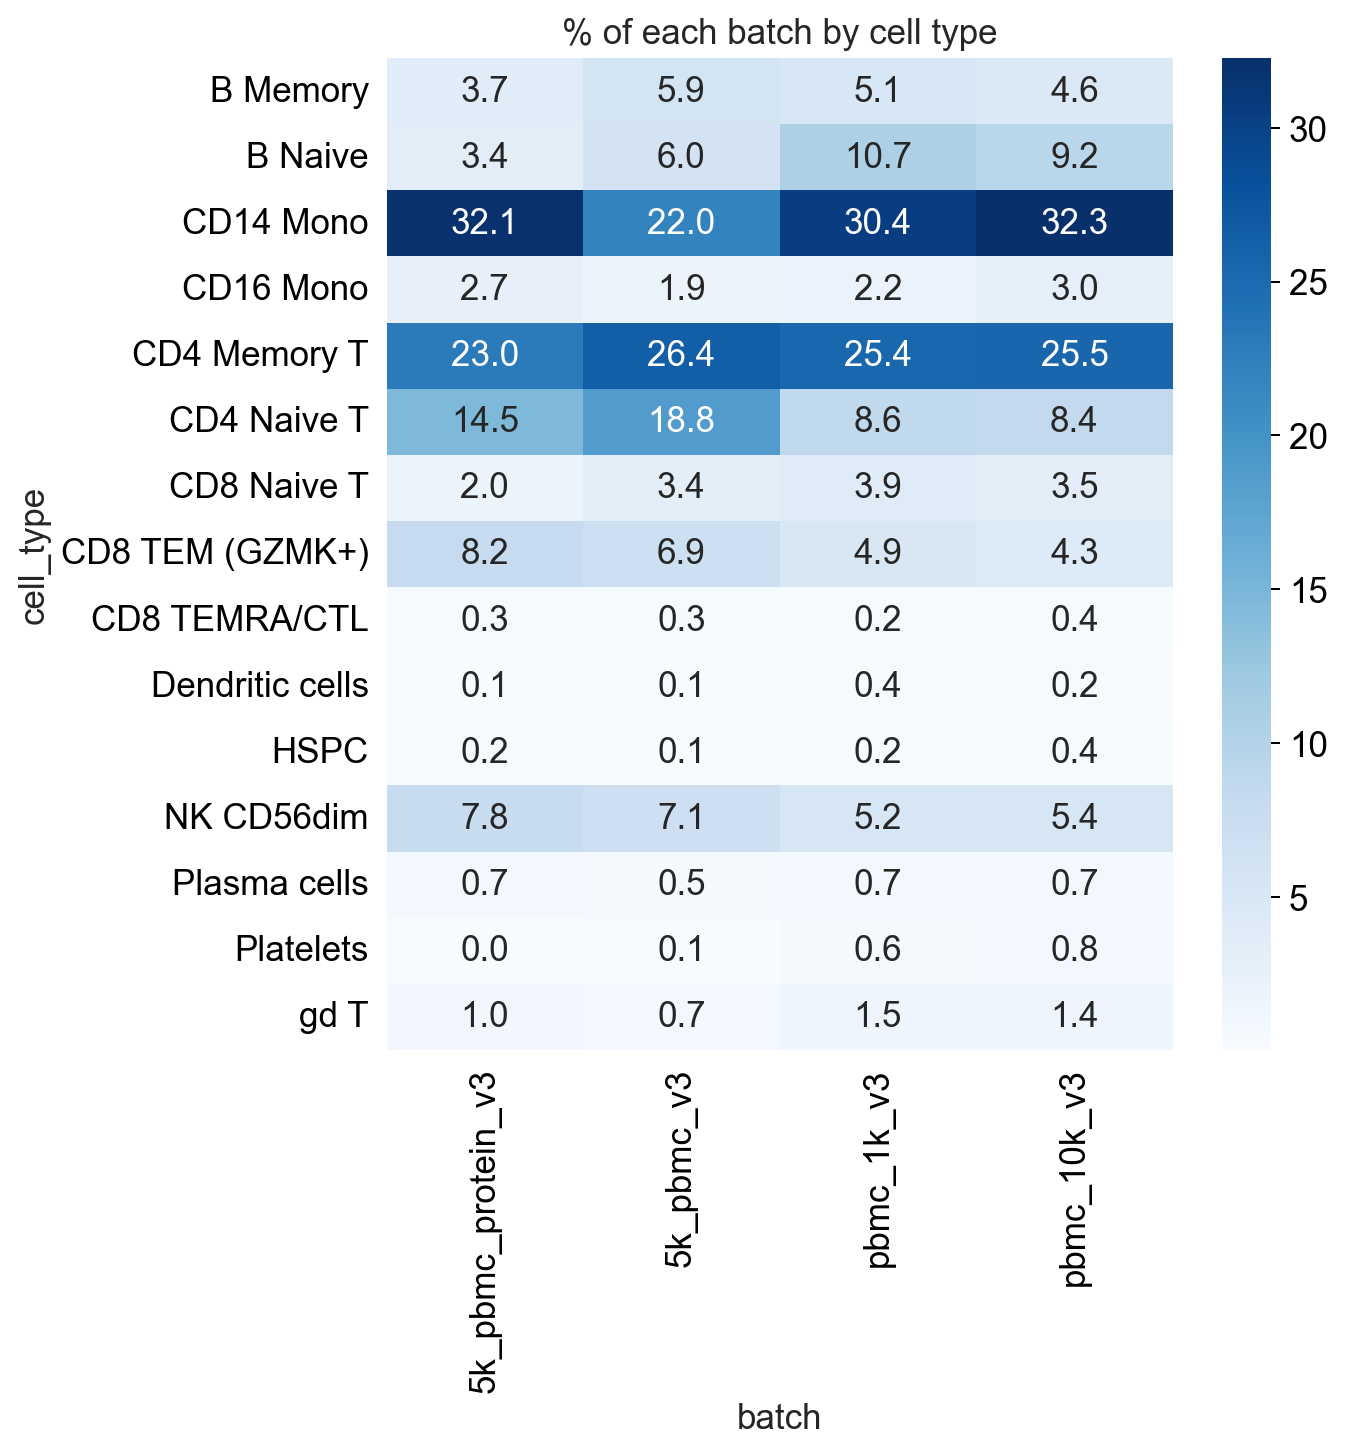

In [84]:
# Show what percent of each batch belongs to each cell type
comp = pd.crosstab(adata.obs["cell_type"], adata.obs["batch"], normalize="columns") * 100
plt.figure(figsize=(7, 0.35 * len(comp) + 2))
sns.heatmap(comp, annot=True, fmt=".1f", cmap="Blues")
plt.title("% of each batch by cell type")
plt.show()

### What this plot shows
For each dataset (column), the percent of its cells that belong to each cell type. Each column adds up to 100.

- All four datasets contain the same cell types in roughly similar proportions. CD14 monocytes make up about 22 to 32% of each, and CD4 Memory T about 23 to 26%. There is no cell type that appears in only one dataset, which suggests the integration worked.
- Some differences remain. CD4 Naive T is 14.5% and 18.8% in the two 5k datasets but about 8.5% in the other two. B Naive is 10.7% in the 1k dataset but 3.4% in 5k_pbmc_protein_v3. CD14 Mono is lower in 5k_pbmc_v3 (22%).
- These differences can come from real differences between the blood donors and how the samples were handled, so they are not necessarily errors.
- Platelets are almost absent in the two 5k datasets (0.0 to 0.1%), which matters later because it leaves too few samples for statistics.

In [85]:
# Compare our labels with CellTypist predictions
import celltypist
from celltypist import models
models.download_models(force_update=False, model=["Immune_All_Low.pkl"])
pred = celltypist.annotate(adata_full, model="Immune_All_Low.pkl", majority_voting=True, over_clustering=adata_full.obs["cluster"].astype(str).values)
adata.obs["celltypist"] = pred.predicted_labels["majority_voting"].reindex(adata.obs_names).values
adata_full.obs["celltypist"] = adata.obs["celltypist"]
xt = pd.crosstab(adata.obs["cell_type"], adata.obs["celltypist"], normalize="index")
for ct in xt.index:
    top = xt.loc[ct].sort_values(ascending=False).head(3)
    print(f"{ct:22s} -> " + " | ".join(f"{k} ({v:.0%})" for k, v in top.items()))

📂 Storing models in /Users/sowmyasivaram/.celltypist/data/models
💾 Total models to download: 1
⏩ Skipping [1/1]: Immune_All_Low.pkl (file exists)
🔬 Input data has 18874 cells and 18727 genes
🔗 Matching reference genes in the model
🧬 5338 features used for prediction
⚖️ Scaling input data
🖋️ Predicting labels
✅ Prediction done!
🗳️ Majority voting the predictions
✅ Majority voting done!


B Memory               -> Memory B cells (99%) | Naive B cells (1%) | CD16+ NK cells (0%)
B Naive                -> Naive B cells (99%) | Memory B cells (1%) | CD16+ NK cells (0%)
CD14 Mono              -> Classical monocytes (84%) | Non-classical monocytes (9%) | DC2 (7%)
CD16 Mono              -> Non-classical monocytes (100%) | CD16+ NK cells (0%) | Classical monocytes (0%)
CD4 Memory T           -> Tcm/Naive helper T cells (78%) | MAIT cells (16%) | Regulatory T cells (6%)
CD4 Naive T            -> Tcm/Naive helper T cells (100%) | Tcm/Naive cytotoxic T cells (0%) | Tem/Trm cytotoxic T cells (0%)
CD8 Naive T            -> Tcm/Naive cytotoxic T cells (99%) | Tcm/Naive helper T cells (1%) | CD16+ NK cells (0%)
CD8 TEM (GZMK+)        -> Tem/Trm cytotoxic T cells (98%) | Tcm/Naive helper T cells (1%) | Tcm/Naive cytotoxic T cells (1%)
CD8 TEMRA/CTL          -> Regulatory T cells (100%) | CD16+ NK cells (0%) | Classical monocytes (0%)
Dendritic cells        -> DC1 (100%) | CD16+ NK cell

## Differential expression
Four analyses:
- One vs rest wilcoxon marker genes for every cell type
- Robustness check
- Pairwise contrasts between related subtypes
- Pseudobulk DESeq2 with batch as a covariate. Single cell tests treat cells as independent replicates and inflate significance; pseudobulk uses the datasets as true replicates.
- Pathway enrichment / GSEA

### One vs rest wilcoxon for every cell type

In [86]:
# Find marker genes for each cell type against all other cells
min_cells_group = 30
counts_per_type = adata_full.obs["cell_type"].value_counts()
valid_types = counts_per_type[counts_per_type >= min_cells_group].index.tolist()
print("Cell types tested:", len(valid_types))
sc.tl.rank_genes_groups(adata_full, groupby="cell_type", groups=valid_types, reference="rest",
                        method="wilcoxon", tie_correct=True, pts=True, key_added="de_wilcoxon")
de_wil = sc.get.rank_genes_groups_df(adata_full, group=None, key="de_wilcoxon")
de_wil["neglog10_padj"] = -np.log10(de_wil["pvals_adj"].clip(lower=1e-300))
de_wil.to_csv("results/de_wilcoxon_all_celltypes.csv", index=False)
markers_sig = de_wil[(de_wil["pvals_adj"] < 0.01) & (de_wil["logfoldchanges"] > 1) & (de_wil["pct_nz_group"] > 0.25)]
print(markers_sig.groupby("group").size().rename("n_significant_markers"))
top_markers = markers_sig.sort_values("scores", ascending=False).groupby("group").head(5)
display(top_markers.groupby("group")["names"].apply(list).to_frame("top5_markers"))

Cell types tested: 14
group
B Memory            248
B Naive             230
CD14 Mono          1458
CD16 Mono          1038
CD4 Memory T        126
CD4 Naive T         134
CD8 Naive T         117
CD8 TEM (GZMK+)     145
CD8 TEMRA/CTL      2172
HSPC               1029
NK CD56dim          416
Plasma cells       1450
Platelets           579
gd T                136
Name: n_significant_markers, dtype: int64


,top5_markers
group,
B Memory,"[TNFRSF13B, IGHG1, IGHG3, BANK1, IGHG2]"
B Naive,"[TCL1A, IGHD, IGHM, CD79A, LINC00926]"
CD14 Mono,"[MNDA, CSTA, VCAN, CD14, MS4A6A]"
CD16 Mono,"[HES4, CDKN1C, CKB, LYPD2, LINC02345]"
CD4 Memory T,"[IL7R, IL32, TRAC, AQP3, CD3D]"
CD4 Naive T,"[FHIT, CCR7, LEF1, TRABD2A, RPS12]"
CD8 Naive T,"[LINC02446, CD8B, CD8A, NELL2, S100B]"
CD8 TEM (GZMK+),"[CD8B, CD8A, CCL5, TRGC2, CST7]"
CD8 TEMRA/CTL,"[SPC25, TYMS, PBK, CDC45, DLGAP5]"


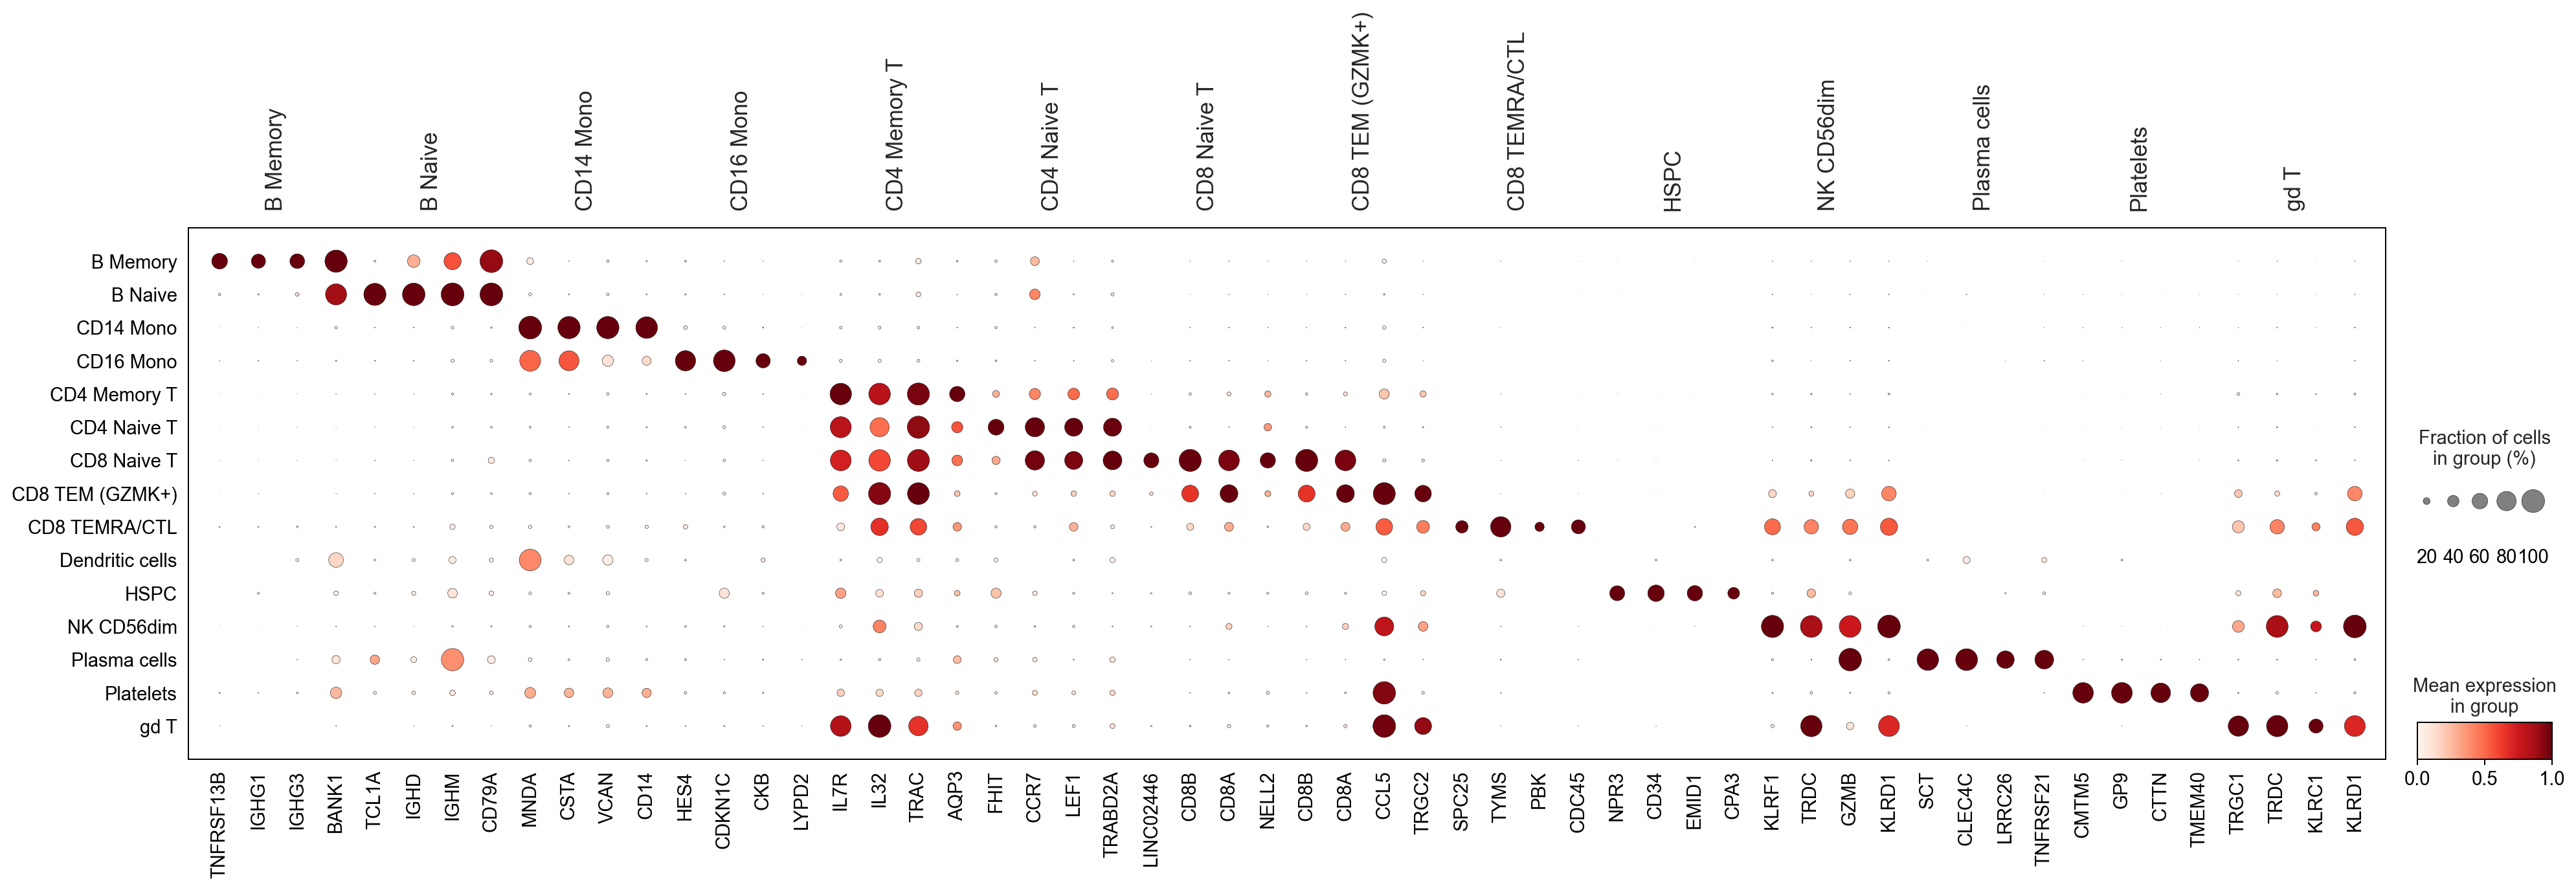

In [87]:
# Plot a dot plot of the top marker genes per cell type
top4 = markers_sig.sort_values("scores", ascending=False).groupby("group").head(4)
top4_dict = {g: d["names"].tolist() for g, d in top4.groupby("group")}
sc.pl.dotplot(adata_full, top4_dict, groupby="cell_type", standard_scale="var", dendrogram=False, figsize=(26, 6))

### What this plot shows
A dot plot of the top 4 marker genes for each cell type, picked by the statistical test.

- A clear diagonal pattern: each type's own genes are dark and large in its own row and small elsewhere. This shows the markers found by the test are specific.
- Clean results: B Naive (TCL1A, IGHD, IGHM), CD14 Mono (MNDA, CSTA, VCAN, CD14), CD16 Mono (HES4, CDKN1C), Platelets (CMTM5, GP9, CTTN, TMEM40) and NK (KLRF1, GZMB, KLRD1).
- Some groups share genes because they are related. The two B types share BANK1 and CD79A, the CD8 types share CD8A and CD8B, and NK, γδ T and CD8 TEM share KLRD1 and TRDC.
- The **CD8 TEMRA/CTL** markers (SPC25, TYMS, PBK, CDC45) are genes of dividing cells, and only some cells in that group express them. The **Plasma cells** markers (SCT, CLEC4C, LRRC26, TNFRSF21) are known plasmacytoid dendritic cell genes. Both labels are therefore doubtful.

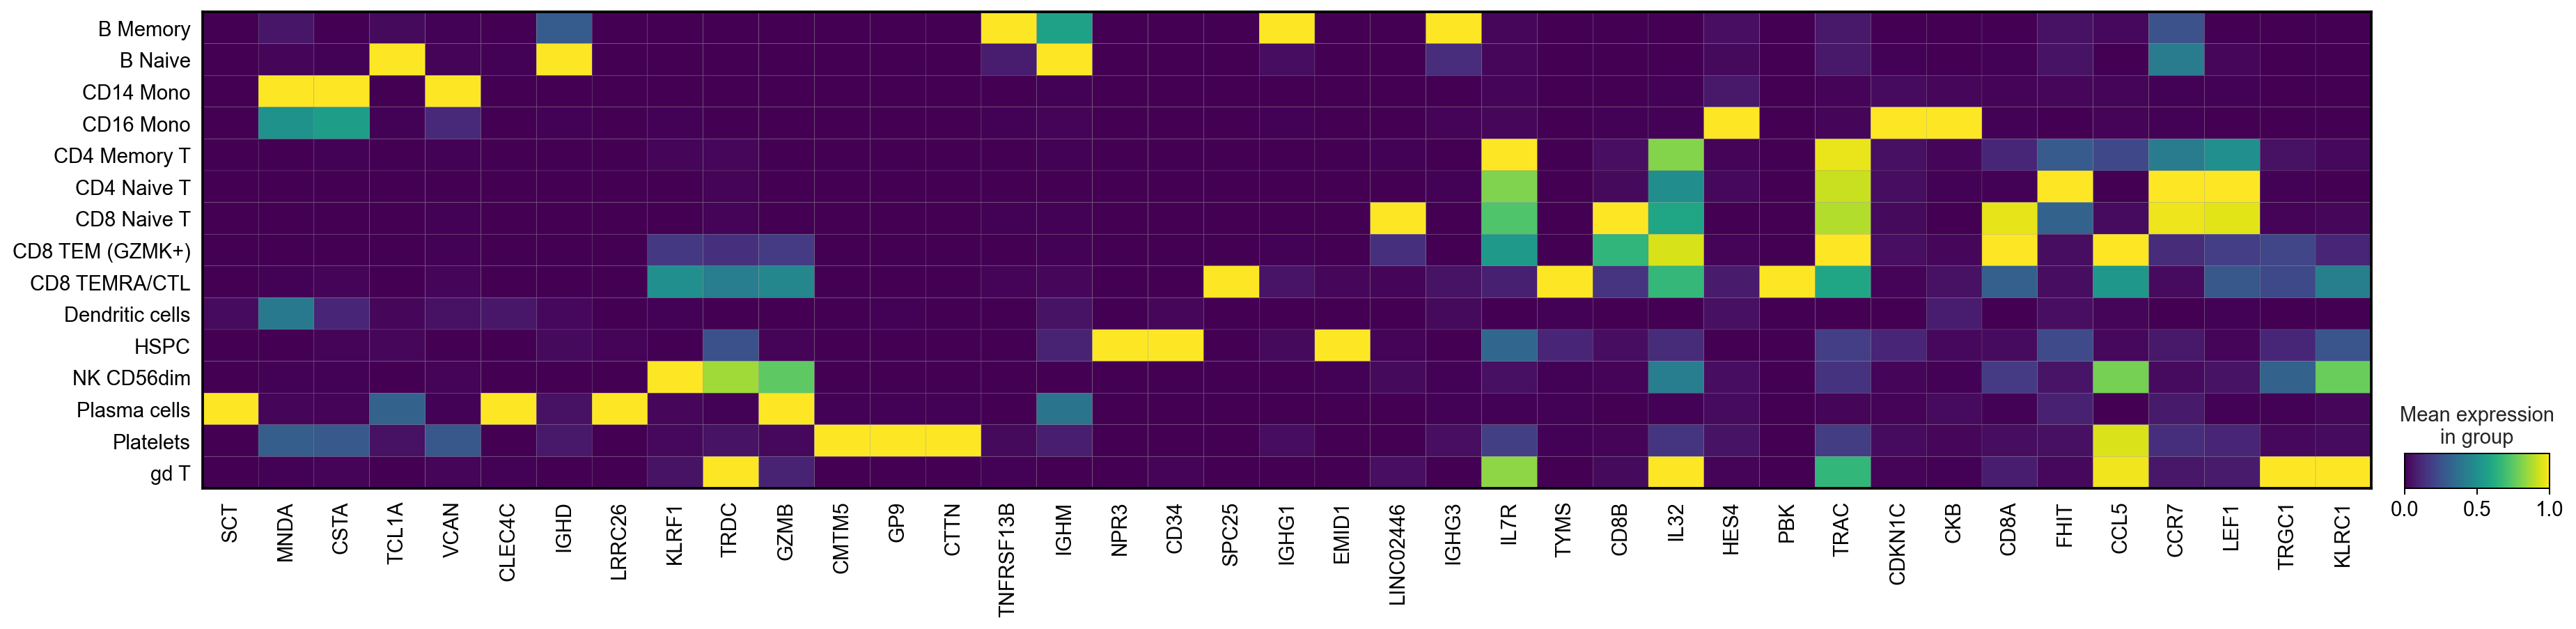

In [88]:
# Plot a heatmap of the top marker genes per cell type
top_for_heatmap = markers_sig.sort_values("scores", ascending=False).groupby("group").head(3)["names"].drop_duplicates().tolist()
sc.pl.matrixplot(adata_full, top_for_heatmap, groupby="cell_type", standard_scale="var", cmap="viridis", figsize=(24, 5))

### What this plot shows
A heatmap of average expression for the top marker genes (columns) in each cell type (rows). Yellow is the highest expression for that gene, and dark purple is the lowest.

- A bright yellow diagonal shows that each cell type has its own set of genes that are high only in that type.
- Related cell types light up together: CD4 and CD8 T cells share TRAC and IL32, and NK cells and γδ T cells share KLRD1 and TRDC.
- The **CD8 TEMRA/CTL** row is yellow only for its cell-division genes (SPC25, TYMS, PBK) and moderately lit across several killer and NK genes, so its identity is mixed.
- Overall this confirms that the labels capture real differences between groups, while the small groups remain the weakest part.

### Robustness- do two different tests agree on the top markers or not

In [89]:
# Check how much two different tests agree on the top markers
sc.tl.rank_genes_groups(adata_full, groupby="cell_type", groups=valid_types, reference="rest",
                        method="t-test_overestim_var", key_added="de_ttest")
de_t = sc.get.rank_genes_groups_df(adata_full, group=None, key="de_ttest")
rows = []
for ct in valid_types:
    a = set(de_wil[de_wil["group"] == ct].sort_values("scores", ascending=False)["names"].head(50))
    b = set(de_t[de_t["group"] == ct].sort_values("scores", ascending=False)["names"].head(50))
    rows.append({"cell_type": ct, "top50_overlap": len(a & b), "jaccard": round(len(a & b) / len(a | b), 2)})
display(pd.DataFrame(rows).set_index("cell_type"))

,top50_overlap,jaccard
cell_type,,
CD14 Mono,39,0.64
CD4 Memory T,45,0.82
CD4 Naive T,46,0.85
B Naive,32,0.47
NK CD56dim,32,0.47
CD8 TEM (GZMK+),40,0.67
B Memory,34,0.52
CD8 Naive T,39,0.64
CD16 Mono,19,0.23


### Pairwise contrasts between related subtypes

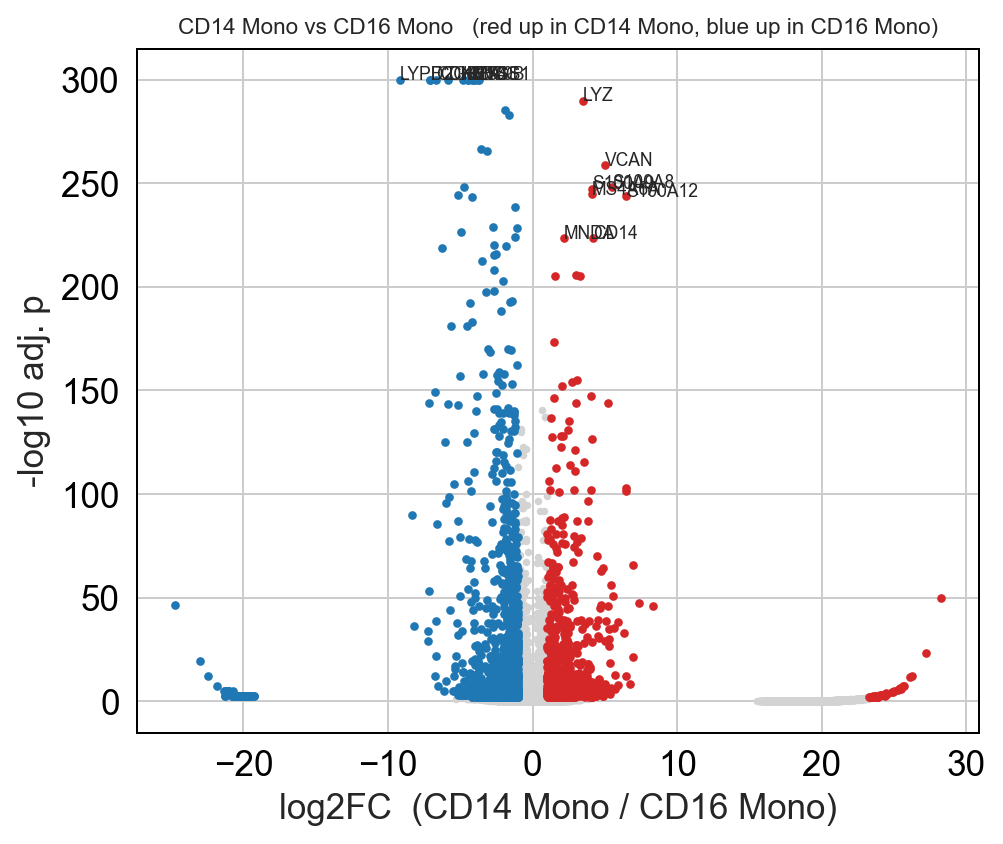

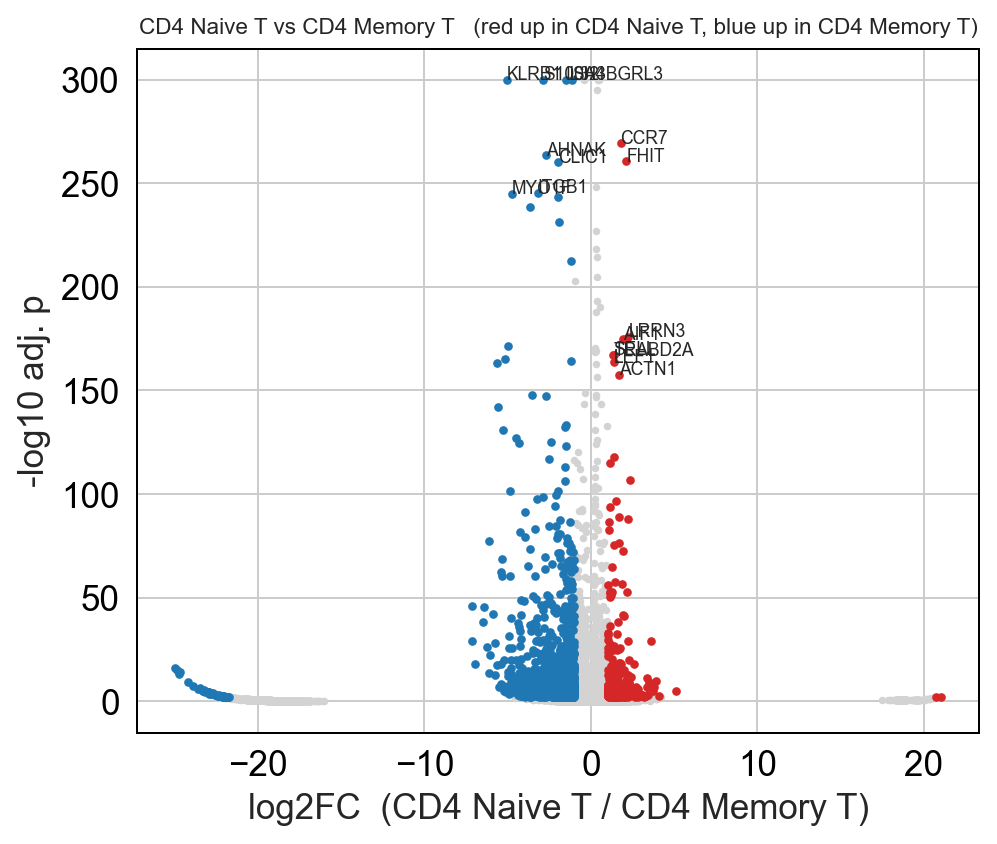

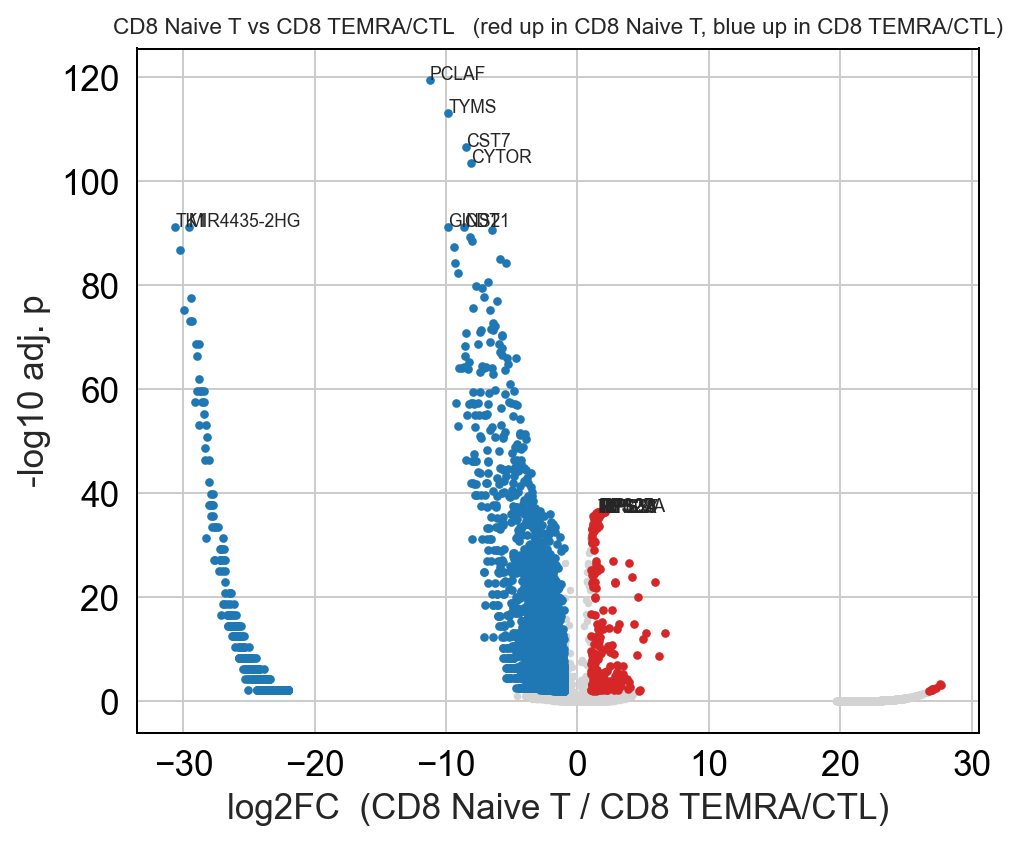

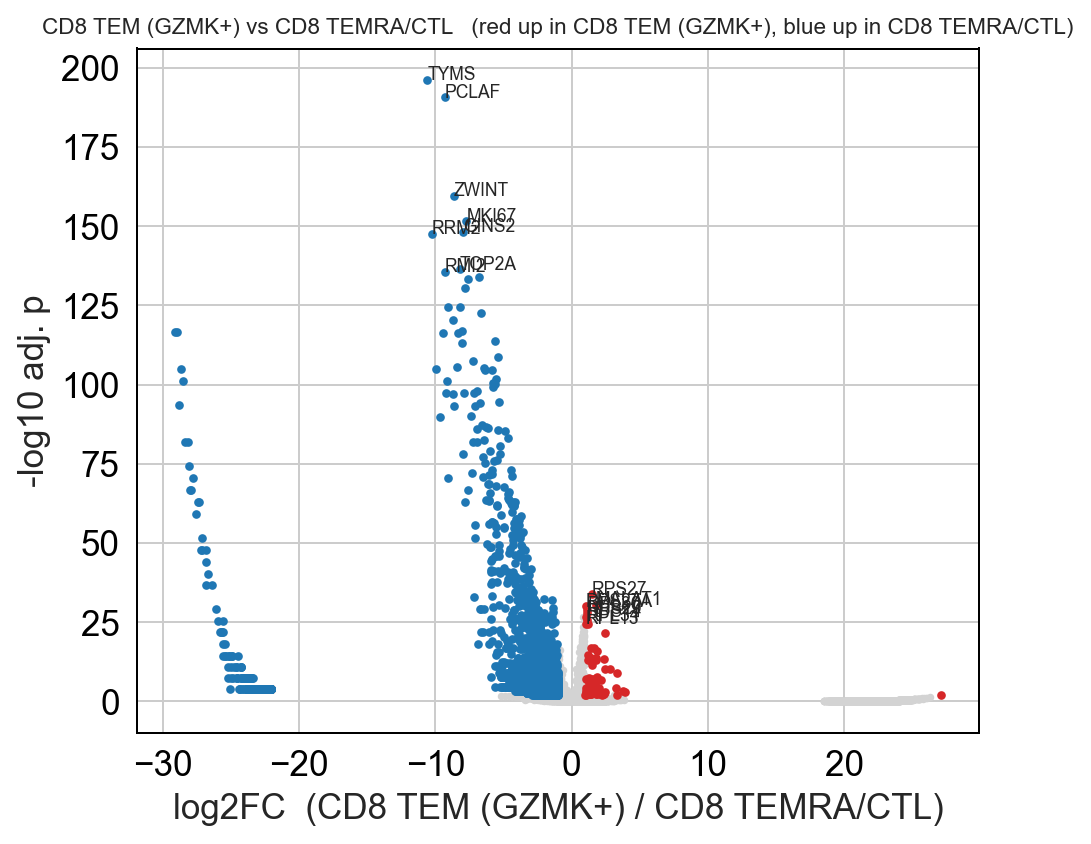

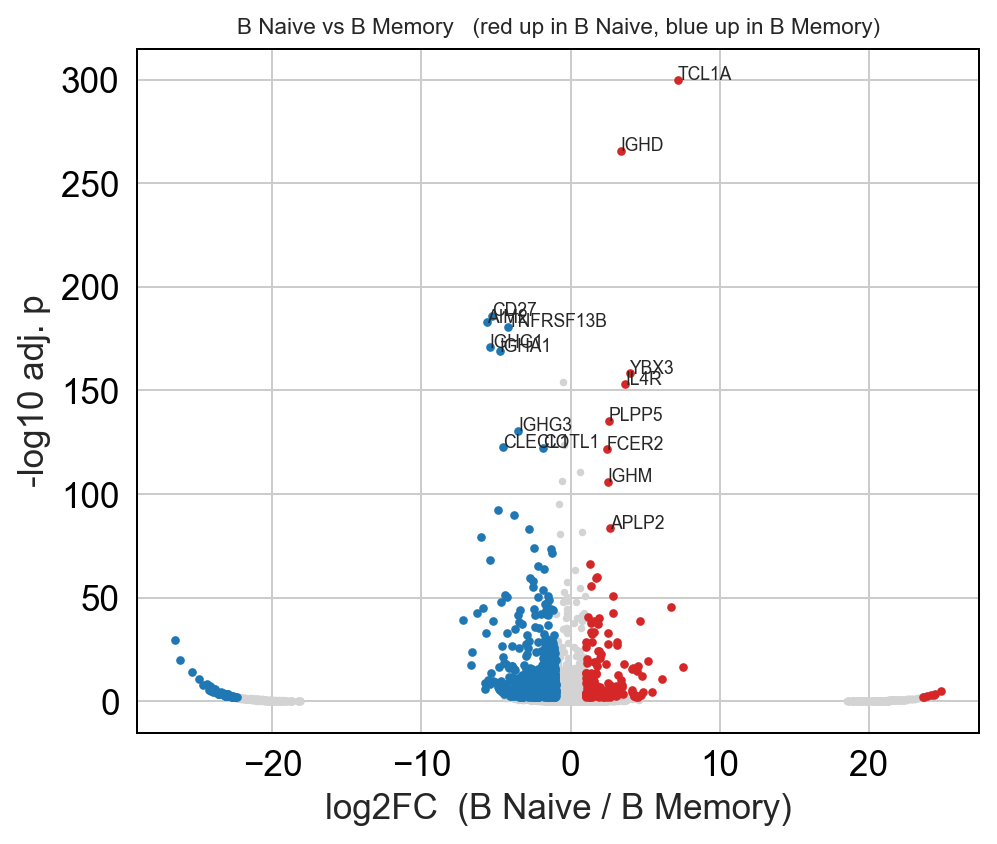

In [90]:
# Compare related cell types directly and draw volcano plots
pairs = [
    ("CD14 Mono", "CD16 Mono"),
    ("CD4 Naive T", "CD4 Memory T"),
    ("CD8 Naive T", "CD8 TEMRA/CTL"),
    ("CD8 TEM (GZMK+)", "CD8 TEMRA/CTL"),
    ("B Naive", "B Memory"),
    ("NK CD56bright", "NK CD56dim"),
]
pairs = [(a, b) for a, b in pairs if a in valid_types and b in valid_types]

pair_results = {}
for a, b in pairs:
    key = f"pair_{a}_vs_{b}"
    sc.tl.rank_genes_groups(adata_full, groupby="cell_type", groups=[a], reference=b, method="wilcoxon", tie_correct=True, pts=True, key_added=key)
    df = sc.get.rank_genes_groups_df(adata_full, group=a, key=key)
    df["neglog10_padj"] = -np.log10(df["pvals_adj"].clip(lower=1e-300))
    pair_results[(a, b)] = df
    df.to_csv(f"results/de_pair_{a}_vs_{b}.csv".replace(" ", "_").replace("/", "-"), index=False)
    sig = (df["pvals_adj"] < 0.01) & (df["logfoldchanges"].abs() > 1)
    fig, ax = plt.subplots(figsize=(6, 5))
    ax.scatter(df["logfoldchanges"], df["neglog10_padj"], s=4, c="lightgrey")
    ax.scatter(df.loc[sig & (df["logfoldchanges"] > 0), "logfoldchanges"], df.loc[sig & (df["logfoldchanges"] > 0), "neglog10_padj"], s=6, c="tab:red")
    ax.scatter(df.loc[sig & (df["logfoldchanges"] < 0), "logfoldchanges"], df.loc[sig & (df["logfoldchanges"] < 0), "neglog10_padj"], s=6, c="tab:blue")
    for _, r in df[sig].sort_values("scores", ascending=False).head(8).iterrows():
        ax.text(r["logfoldchanges"], r["neglog10_padj"], r["names"], fontsize=7)
    for _, r in df[sig].sort_values("scores").head(8).iterrows():
        ax.text(r["logfoldchanges"], r["neglog10_padj"], r["names"], fontsize=7)
    ax.set_xlabel(f"log2FC  ({a} / {b})")
    ax.set_ylabel("-log10 adj. p")
    ax.set_title(f"{a} vs {b}   (red up in {a}, blue up in {b})", fontsize=9)
    plt.show()

### What these plots show
Five volcano plots comparing related cell types head to head. Each dot is a gene. The x axis is the fold change on a log2 scale, and 1 means twice as high. The y axis is how significant the difference is, and higher is stronger. Red genes are significantly higher in the first cell type of the title, and blue genes are significantly higher in the second.

1. **CD14 Mono vs CD16 Mono:** classical monocyte genes such as LYZ, VCAN and CD14 are on the red side. Many CD16 genes reach the top of the plot, which is a ceiling set by the code at 300.
2. **CD4 Naive T vs CD4 Memory T:** CCR7 and FHIT stand out on the naive side. The memory side has many more significant genes, including AHNAK and CLIC1, so memory cells have a broader set of active genes. Fold changes are modest.
3. **CD8 Naive T vs CD8 TEMRA/CTL:** the strongest blue genes (TYMS, PCLAF) are cell-division genes.
4. **CD8 TEM (GZMK+) vs CD8 TEMRA/CTL:** again the top genes on the TEMRA/CTL side are cell-division genes (TYMS, PCLAF, ZWINT, MKI67, TOP2A). This is strong evidence that the "CD8 TEMRA/CTL" group is a group of dividing cells and not a true cytotoxic type.
5. **B Naive vs B Memory:** TCL1A, IGHD, IGHM, FCER2 and IL4R are higher in naive cells, and CD27, TNFRSF13B and the antibody genes IGHG1, IGHA1 and IGHG3 are higher in memory cells. This is the expected biology.

**Reading note:** the dots far out at about ±20 to 30 on the x axis are genes that are nearly absent in one group, which gives exaggerated fold changes. They are not meaningful. Also, this test counts every cell as an independent sample, so its significance values are overstated.

### Pseudobulk differential expression with PyDESeq2

In [91]:
# Sum counts per cell type and batch to build pseudobulk samples
from pydeseq2.dds import DeseqDataSet
from pydeseq2.ds import DeseqStats
import inspect
min_cells_sample = 20
counts_mat = adata_full.layers["counts"]

pb_rows, pb_meta = [], []
for b in adata_full.obs["batch"].cat.categories:
    for ct in valid_types:
        m = ((adata_full.obs["batch"] == b) & (adata_full.obs["cell_type"] == ct)).values
        if m.sum() == 0:
            continue
        pb_rows.append(np.asarray(counts_mat[m].sum(axis=0)).ravel())
        pb_meta.append({"sample": f"{b}|{ct}", "batch": b, "cell_type": ct, "n_cells": int(m.sum())})

pb_meta = pd.DataFrame(pb_meta).set_index("sample")
pb_counts = pd.DataFrame(np.vstack(pb_rows).astype(int), index=pb_meta.index, columns=adata_full.var_names)
print(pb_counts.shape)
display(pb_meta.pivot(index="cell_type", columns="batch", values="n_cells"))

(56, 18727)


batch,5k_pbmc_protein_v3,5k_pbmc_v3,pbmc_10k_v3,pbmc_1k_v3
cell_type,,,,
B Memory,147,245,451,52
B Naive,135,250,898,108
CD14 Mono,1265,921,3142,308
CD16 Mono,108,80,290,22
CD4 Memory T,907,1104,2483,257
CD4 Naive T,572,785,815,87
CD8 Naive T,80,142,344,39
CD8 TEM (GZMK+),323,289,414,50
CD8 TEMRA/CTL,12,12,37,2


In [92]:
# Run pseudobulk DESeq2 for each pair of related cell types
pb_pair_results = {}
for a, b in pairs:
    sel = pb_meta[(pb_meta["cell_type"].isin([a, b])) & (pb_meta["n_cells"] >= min_cells_sample)]
    if (sel["cell_type"] == a).sum() < 2 or (sel["cell_type"] == b).sum() < 2:
        print(f"Skipping {a} vs {b}: fewer than 2 replicates per group")
        continue

    counts = pb_counts.loc[sel.index]
    counts = counts.loc[:, counts.sum(axis=0) >= 10]
    meta = sel[["batch", "cell_type"]].rename(columns={"cell_type": "condition"}).astype(str)
    design_arg = {"design_factors": ["batch", "condition"]}
    dds = DeseqDataSet(counts=counts, metadata=meta, quiet=True, **design_arg)
    dds.deseq2()
    dds.design_factors = ["batch", "condition"]
    stats = DeseqStats(dds, contrast=["condition", a, b], quiet=True)
    stats.summary()
    res = stats.results_df.sort_values("padj")
    pb_pair_results[(a, b)] = res
    res.to_csv(f"results/pseudobulk_{a}_vs_{b}.csv".replace(" ", "_").replace("/", "-"))
    print(f"{a} vs {b}: {int((res['padj'] < 0.05).sum())} genes at padj<0.05 | {len(sel)} pseudobulk samples")

CD14 Mono vs CD16 Mono: 3059 genes at padj<0.05 | 8 pseudobulk samples
CD4 Naive T vs CD4 Memory T: 2084 genes at padj<0.05 | 8 pseudobulk samples
Skipping CD8 Naive T vs CD8 TEMRA/CTL: fewer than 2 replicates per group
Skipping CD8 TEM (GZMK+) vs CD8 TEMRA/CTL: fewer than 2 replicates per group
B Naive vs B Memory: 866 genes at padj<0.05 | 8 pseudobulk samples


In [93]:
# Run pseudobulk DESeq2 for each cell type against the rest
batch_totals = pb_counts.groupby(pb_meta["batch"]).sum()
pb_ovr_results = {}
for ct in valid_types:
    samples = pb_meta[(pb_meta["cell_type"] == ct) & (pb_meta["n_cells"] >= min_cells_sample)]
    if len(samples) < 2:
        continue
    rows, meta_rows = [], []
    for s, r in samples.iterrows():
        rows.append(pb_counts.loc[s].values)
        meta_rows.append({"sample": f"{r['batch']}|{ct}", "batch": r["batch"], "condition": ct})
        rows.append((batch_totals.loc[r["batch"]] - pb_counts.loc[s]).values)
        meta_rows.append({"sample": f"{r['batch']}|rest", "batch": r["batch"], "condition": "rest"})

    meta = pd.DataFrame(meta_rows).set_index("sample")
    counts = pd.DataFrame(np.vstack(rows).astype(int), index=meta.index, columns=pb_counts.columns)
    counts = counts.loc[:, counts.sum(axis=0) >= 10]

    design_arg = {"design_factors": ["batch", "condition"]}
    dds = DeseqDataSet(counts=counts, metadata=meta, quiet=True, **design_arg)
    dds.deseq2()
    dds.design_factors = ["batch", "condition"]
    stats = DeseqStats(dds, contrast=["condition", ct, "rest"], quiet=True)
    stats.summary()
    res = stats.results_df.sort_values("padj")
    pb_ovr_results[ct] = res
    res.to_csv(f"results/pseudobulk_{ct}_vs_rest.csv".replace(" ", "_").replace("/", "-"))
    print(f"{ct:22s} {int(((res['padj'] < 0.05) & (res['log2FoldChange'] > 1)).sum()):5d} up genes (padj<0.05, log2FC>1)")

CD14 Mono               2526 up genes (padj<0.05, log2FC>1)
CD4 Memory T            1431 up genes (padj<0.05, log2FC>1)
CD4 Naive T             1143 up genes (padj<0.05, log2FC>1)
B Naive                 1513 up genes (padj<0.05, log2FC>1)
NK CD56dim              1143 up genes (padj<0.05, log2FC>1)
CD8 TEM (GZMK+)          709 up genes (padj<0.05, log2FC>1)
B Memory                1252 up genes (padj<0.05, log2FC>1)
CD8 Naive T             1012 up genes (padj<0.05, log2FC>1)
CD16 Mono                893 up genes (padj<0.05, log2FC>1)
gd T                     352 up genes (padj<0.05, log2FC>1)
Plasma cells            1176 up genes (padj<0.05, log2FC>1)


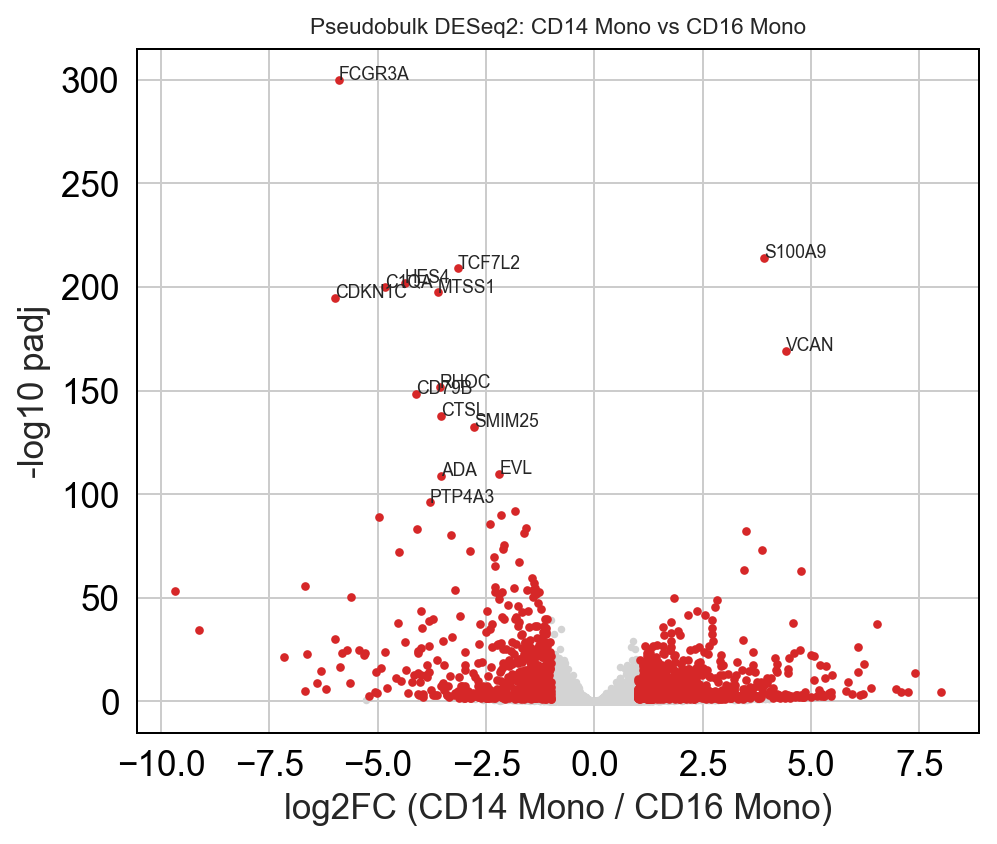

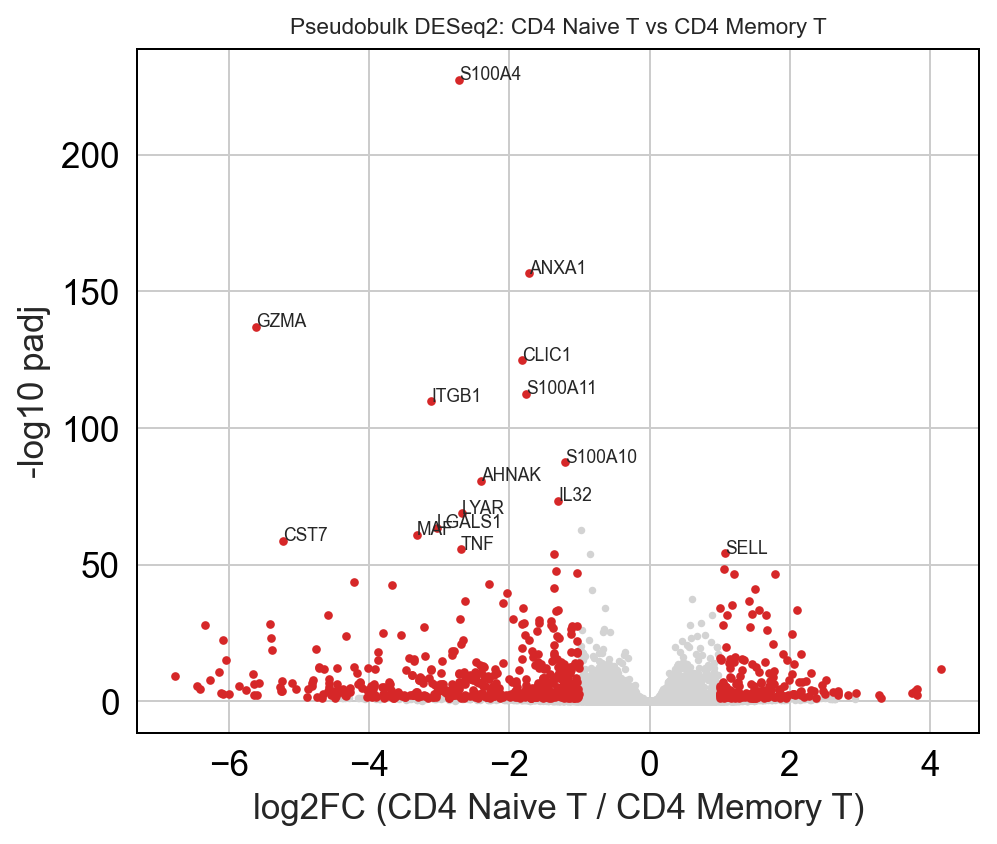

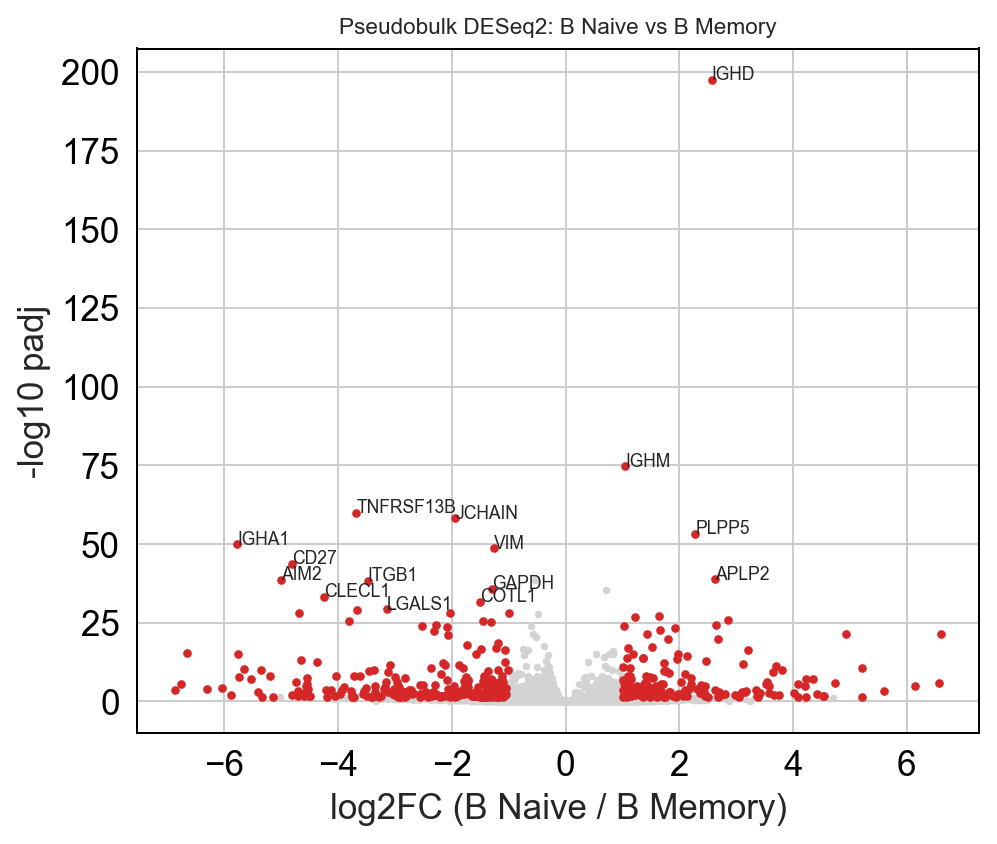

In [94]:
# Draw volcano plots for the pseudobulk pair comparisons
for (a, b), res in pb_pair_results.items():
    r = res.dropna(subset=["padj"]).copy()
    r["nl"] = -np.log10(r["padj"].clip(lower=1e-300))
    sig = (r["padj"] < 0.05) & (r["log2FoldChange"].abs() > 1)
    fig, ax = plt.subplots(figsize=(6, 5))
    ax.scatter(r["log2FoldChange"], r["nl"], s=4, c="lightgrey")
    ax.scatter(r.loc[sig, "log2FoldChange"], r.loc[sig, "nl"], s=6, c="tab:red")
    for g, row in r[sig].sort_values("nl", ascending=False).head(15).iterrows():
        ax.text(row["log2FoldChange"], row["nl"], g, fontsize=7)
    ax.set_xlabel(f"log2FC ({a} / {b})")
    ax.set_ylabel("-log10 padj")
    ax.set_title(f"Pseudobulk DESeq2: {a} vs {b}", fontsize=9)
    plt.show()

### What these plots show
Volcano plots for the pseudobulk DESeq2 comparisons, where each dataset counts as one replicate. Each dot is a gene. All significant genes are red, on both sides. A positive x value means higher in the first cell type of the title, and a negative value means higher in the second.

1. **CD14 Mono vs CD16 Mono:** S100A9 and VCAN are high in CD14 monocytes. FCGR3A, CDKN1C, TCF7L2, HES4 and MTSS1 are high in CD16 monocytes. These are the known defining genes of the two types.
2. **CD4 Naive T vs CD4 Memory T:** the strongest differences are on the memory side (S100A4, ANXA1, GZMA, CLIC1, S100A11, IL32), and SELL is higher in naive cells. S100A4 and ANXA1 are classic memory T cell genes.
3. **B Naive vs B Memory:** IGHD and IGHM are higher in naive B cells. CD27, TNFRSF13B, IGHA1 and AIM2 are higher in memory B cells.

**What this tells us:** the top genes are the textbook markers of each cell type, which is more convincing than the cell-by-cell test above. The fold changes are in a sensible range, with none of the extreme artifacts from the earlier plots, but each result rests on only 4 datasets, so it has limited statistical power.

In [95]:
# Check how much pseudobulk and single cell markers agree
rows = []
for ct, res in pb_ovr_results.items():
    pb_top = set(res[res["log2FoldChange"] > 0].dropna(subset=["padj"]).sort_values("padj").head(50).index)
    w_top = set(de_wil[de_wil["group"] == ct].sort_values("scores", ascending=False)["names"].head(50))
    rows.append({"cell_type": ct, "overlap_top50": len(pb_top & w_top)})
display(pd.DataFrame(rows).set_index("cell_type"))

,overlap_top50
cell_type,
CD14 Mono,26
CD4 Memory T,11
CD4 Naive T,10
B Naive,34
NK CD56dim,35
CD8 TEM (GZMK+),32
B Memory,20
CD8 Naive T,22
CD16 Mono,29


### Pathway enrichment and GSEA

In [97]:
# Run pathway enrichment on the pairwise pseudobulk results
import gseapy as gp
gsea_results = {}
for (a, b), res in pb_pair_results.items():
    rnk = res["stat"].dropna().sort_values(ascending=False)
    pre = gp.prerank(rnk=rnk, gene_sets="MSigDB_Hallmark_2020", min_size=10, max_size=500,
                     permutation_num=1000, seed=0, threads=4, outdir=None, verbose=False)
    out = pre.res2d[["Term", "NES", "FDR q-val"]].copy()
    out["NES"] = out["NES"].astype(float)
    out["FDR q-val"] = out["FDR q-val"].astype(float)
    gsea_results[(a, b)] = out.sort_values("NES", ascending=False)
    out.to_csv(f"results/gsea_hallmark_{a}_vs_{b}.csv".replace(" ", "_").replace("/", "-"), index=False)

    print(f"\n=== {a} vs {b}: enriched in {a} (top) / in {b} (bottom), FDR<0.25 ===")
    sig = gsea_results[(a, b)].query("`FDR q-val` < 0.25")
    display(pd.concat([sig.head(5), sig.tail(5)]).drop_duplicates())

2026-11-08 15:03:28,879 [WARNING] Duplicated values found in preranked stats: 1.18% of genes
The order of those genes will be arbitrary, which may produce unexpected results.



=== CD14 Mono vs CD16 Mono: enriched in CD14 Mono (top) / in CD16 Mono (bottom), FDR<0.25 ===


,Term,NES,FDR q-val
1,TNF-alpha Signaling via NF-kB,1.968232,0.000000
2,Epithelial Mesenchymal Transition,1.915383,0.000645
7,Glycolysis,1.554958,0.049905
8,Angiogenesis,1.541589,0.042591
9,Hypoxia,1.497787,0.055240
6,Notch Signaling,-1.564670,0.035693
5,Oxidative Phosphorylation,-1.609000,0.028538
4,Pancreas Beta Cells,-1.618994,0.035103
3,Interferon Gamma Response,-1.656668,0.032155
0,Interferon Alpha Response,-2.123085,0.000000


2026-11-08 15:03:30,304 [WARNING] Duplicated values found in preranked stats: 0.26% of genes
The order of those genes will be arbitrary, which may produce unexpected results.



=== CD4 Naive T vs CD4 Memory T: enriched in CD4 Naive T (top) / in CD4 Memory T (bottom), FDR<0.25 ===


,Term,NES,FDR q-val
17,Myc Targets V1,1.662938,0.015577
22,Wnt-beta Catenin Signaling,1.583716,0.018560
33,Myc Targets V2,1.252574,0.150029
37,heme Metabolism,-1.178351,0.235976
36,Bile Acid Metabolism,-1.189215,0.226540
4,Apoptosis,-2.148745,0.000000
3,IL-2/STAT5 Signaling,-2.154813,0.000000
2,Complement,-2.162424,0.000000
1,Epithelial Mesenchymal Transition,-2.250840,0.000000
0,Interferon Gamma Response,-2.269174,0.000000


2026-11-08 15:03:31,724 [WARNING] Duplicated values found in preranked stats: 0.27% of genes
The order of those genes will be arbitrary, which may produce unexpected results.



=== B Naive vs B Memory: enriched in B Naive (top) / in B Memory (bottom), FDR<0.25 ===


,Term,NES,FDR q-val
6,KRAS Signaling Up,1.588887,0.070774
19,Estrogen Response Late,1.421769,0.138810
23,TNF-alpha Signaling via NF-kB,1.346769,0.156433
26,Mitotic Spindle,-1.238900,0.220767
25,Myc Targets V2,-1.258524,0.203514
4,Reactive Oxygen Species Pathway,-1.738469,0.012460
3,Apical Junction,-1.787995,0.007788
2,Epithelial Mesenchymal Transition,-1.798470,0.008578
1,Myc Targets V1,-1.880078,0.006772
0,Oxidative Phosphorylation,-2.338556,0.000000


In [98]:
# Find enriched biological processes for each cell type marker list
for ct, res in pb_ovr_results.items():
    genes = res[(res["padj"] < 0.01) & (res["log2FoldChange"] > 1)].sort_values("padj").head(150).index.tolist()
    if len(genes) < 15:
        continue
    enr = gp.enrichr(gene_list=genes, gene_sets=["GO_Biological_Process_2023"], organism="human", outdir=None).results
    best = enr.sort_values("Adjusted P-value").head(3)
    print(f"\n{ct}")
    for t, p in zip(best["Term"], best["Adjusted P-value"]):
        print(f"   {t}  (adj p={p:.1e})")


CD14 Mono
   Inflammatory Response (GO:0006954)  (adj p=4.3e-06)
   Regulation Of Interleukin-1 Beta Production (GO:0032651)  (adj p=7.1e-06)
   Positive Regulation Of Phagocytosis (GO:0050766)  (adj p=7.1e-06)

CD4 Memory T
   T Cell Activation (GO:0042110)  (adj p=2.6e-09)
   T Cell Receptor Signaling Pathway (GO:0050852)  (adj p=1.4e-06)
   Antigen Receptor-Mediated Signaling Pathway (GO:0050851)  (adj p=2.1e-06)

CD4 Naive T
   Cytoplasmic Translation (GO:0002181)  (adj p=5.8e-26)
   Peptide Biosynthetic Process (GO:0043043)  (adj p=1.3e-20)
   Macromolecule Biosynthetic Process (GO:0009059)  (adj p=1.3e-20)

B Naive
   B Cell Receptor Signaling Pathway (GO:0050853)  (adj p=2.7e-11)
   B Cell Activation (GO:0042113)  (adj p=4.1e-08)
   Antigen Receptor-Mediated Signaling Pathway (GO:0050851)  (adj p=1.1e-07)

NK CD56dim
   Regulation Of Natural Killer Cell Mediated Cytotoxicity (GO:0042269)  (adj p=8.7e-08)
   Positive Regulation Of Natural Killer Cell Mediated Immunity (GO:000271

## 12. Save results

In [99]:
# Save the annotated data and result tables
adata_full.write_h5ad("results/pbmc_integrated_annotated.h5ad")

summary = adata_full.obs.groupby(["cell_type"], observed=True).size().rename("n_cells").to_frame()
summary["pct"] = (summary["n_cells"] / summary["n_cells"].sum() * 100).round(2)
summary.to_csv("results/cell_type_summary.csv")
display(summary.sort_values("n_cells", ascending=False))

pd.concat({f"{a}_vs_{b}": r for (a, b), r in pb_pair_results.items()}).to_csv("results/pseudobulk_all_pairs.csv")
print("Saved to ./results")

,n_cells,pct
cell_type,,
CD14 Mono,5636,29.86
CD4 Memory T,4751,25.17
CD4 Naive T,2259,11.97
B Naive,1391,7.37
NK CD56dim,1181,6.26
CD8 TEM (GZMK+),1076,5.70
B Memory,895,4.74
CD8 Naive T,605,3.21
CD16 Mono,500,2.65


Saved to ./results
